# Milestone 2 — M5 Demand Forecasting

**Group 2 - MIA5130A Systems Optimization and Management**

This notebook implements **Parts 1–4** for the ten selected food products at **CA_1**:
set the experiment, prepare the weekly dataset, train and compare models, and
evaluate their held-out test forecasts. It includes training-period product
selection, chronological splits, past-only features, leakage checks, and
seasonal-naive, four-week-average, polynomial, and lag-based ridge forecasts.

Hyperparameters use chronological folds within training. The separate eight-week
validation window selects the model family. The final 56-week test comparison
keeps those settings and coefficients fixed, reports MAE/RMSE/WAPE overall and by
product/quarter, and assesses the proposed 10% improvement target. Interval
calibration settings are frozen from validation before test scoring.
**Part 5 (test intervals, coverage, and uncertainty plots) and Part 6 (the final
submission report) remain unfinished.**

Run this notebook top to bottom in a fresh **Python 3.15 (M5 exploration)** kernel.
The setup loads the raw M5 CSV files directly; Milestone 1 does not need to run
first. The saved copy includes executed tables and figures.

The earlier exploration remains in
[Milestone 1](M5_Milestone_1_Data_Exploration_and_Understanding.ipynb).
Prepared data are in `outputs/milestone2/`, validation models and parameters in
`outputs/milestone2/models/`, and test results in `outputs/milestone2/evaluation/`.

## Contents

1. [Setup and source files](#m2-setup)
2. [Set the experiment](#milestone-2)
3. [Prepare the final dataset](#milestone-2-dataset)
4. [Train and compare models — Part 3](#milestone-2-models)
5. [Evaluate forecasts — Part 4](#milestone-2-evaluation)


<a id="m2-setup"></a>

## 1 Setup and source files

Use the project environment and versions in `requirements.txt`. Set
`DATA_DIR_OVERRIDE` in the next cell if needed, or set the `M5_DATA_DIR` environment
variable. The notebook also checks the project's `data/` folder and
`~/Downloads/m5-forecasting-accuracy`.

Milestone 2 reads `calendar.csv`, `sales_train_evaluation.csv`, and `sell_prices.csv`.
Sales and price files are read in chunks, retaining only the required records.
Source files are read in place and checked for changes during preparation.


In [1]:
from pathlib import Path
import os
import sys
import platform
import tempfile
import importlib.metadata as metadata
from packaging.version import Version

# Use the same tested environment as Milestone 1, with independent kernel state.
if sys.version_info[:2] == (3, 15):
    for package, minimum in [("numpy", "2.5.4"), ("pandas", "3.1.1")]:
        installed = metadata.version(package)
        if Version(installed) < Version(minimum):
            raise RuntimeError(
                f"This notebook's Python 3.15 setup requires {package}>={minimum}; "
                f"this kernel has {installed}. Install the project's requirements.txt "
                "with this interpreter, then restart the kernel. Interpreter: " + sys.executable
            )

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "m5-matplotlib-cache"))
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

%matplotlib inline

DATA_DIR_OVERRIDE = None  # Example: Path("/path/to/m5-forecasting-accuracy")
PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
required_files = ["calendar.csv", "sales_train_evaluation.csv", "sell_prices.csv"]
candidates = ([Path(DATA_DIR_OVERRIDE).expanduser()] if DATA_DIR_OVERRIDE else [])
if os.environ.get("M5_DATA_DIR"):
    candidates.append(Path(os.environ["M5_DATA_DIR"]).expanduser())
candidates += [PROJECT_DIR / "data", PROJECT_DIR / "m5-forecasting-accuracy",
               PROJECT_DIR.parent / "m5-forecasting-accuracy",
               Path.home() / "Downloads" / "m5-forecasting-accuracy"]
DATA_DIR = next((p.resolve() for p in candidates if all((p / f).is_file() for f in required_files)), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Set DATA_DIR_OVERRIDE to the folder containing calendar.csv, "
        "sales_train_evaluation.csv, and sell_prices.csv."
    )

pd.set_option("display.max_columns", 14)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
versions = {package: metadata.version(package) for package in ["numpy", "pandas", "matplotlib", "ipykernel"]}
versions["python"] = platform.python_version()
print("Python:", platform.python_version(), "| Interpreter:", sys.executable)
print("Data folder:", DATA_DIR.name)
print("Milestone 2 outputs: ./outputs/milestone2/ under this notebook's working directory")
display(pd.Series(versions, name="Executed versions").to_frame())


Python: 3.15.0 | Interpreter: /Users/hshazel/Projects/m5-data-exploration/.venv/bin/python
Data folder: m5-forecasting-accuracy
Milestone 2 outputs: ./outputs/milestone2/ under this notebook's working directory


,Executed versions
numpy,2.5.4
pandas,3.1.1
matplotlib,3.11.2
ipykernel,7.4.0
python,3.15.0


<a id="milestone-2"></a>

## 2 Set the experiment

This section defines the Milestone 2 experiment for **ten food products at store
CA_1 in California**, forecasting the total units sold during the next complete
Monday-Sunday week. The selected products and dates below are the working
configuration for Milestone 2. The work plan below summarizes the activities and deliverables.

Sections 8-10 of [Milestone 1](M5_Milestone_1_Data_Exploration_and_Understanding.ipynb) record the earlier exploratory
experiment, with a different shortlist and four-week validation and test periods.
Their tables, exports, and baseline scores describe that earlier experiment.
Use the configuration in this notebook for the final Milestone 2 dataset.

| Decision | Milestone 2 specification |
|---|---|
| Store and state | CA_1, California |
| Category | FOODS; the ten product codes listed in the selection audit below |
| Unit of prediction | One product at one store for one target week |
| Forecast origin | End of Sunday, immediately before the target week |
| Target | Sum of observed unit sales during the following Monday-Sunday week |
| Forecast horizon | Seven days; one weekly total per product |
| Evaluation schedule | Make a new one-week-ahead forecast each week |
| Inventory connection | Supply ten weekly product forecasts for the later 100-unit inventory scenario |

For example, the forecast issued at the end of **Sunday, March 1, 2015** predicts
sales during **March 2-8, 2015**. A later forecast can use earlier validation or
test weeks once those sales have occurred. This is a sequence of weekly forecasts,
not a forecast of the entire test year made at one date.

Only information available at each forecast origin may enter the inputs. Historical
sales features must stop at the origin. Treat a recorded weekly average price as
available after its retail week ends, and carry the last available price forward
unless a known future price plan is explicitly supplied. Known calendar inputs use
the California SNAP flag. Hyperparameter tuning uses chronological validation folds inside training;
the separate validation period selects the model family. Keep test outcomes
out of both decisions.

Recorded sales are a proxy for demand because stockouts and unmet demand are not
observed. This case study represents frequently sold food products at one store;
its results do not establish performance across all M5 products or locations.

### 2.1 Configuration and split dates

The complete observed history contains 277 Monday-Sunday weeks. Reserve the final
**56 weeks (20.2%) for testing**. The earlier 221 weeks form the development period,
with its last **eight weeks reserved for validation**, leaving **213 training
weeks**. This implements the proposal's approximate 80/20 chronological design
while adding a separate validation period inside the earlier 80%.

The opening January 29-30, 2011 partial week is excluded. Counts below are calendar
windows before feature warm-up or selling-history filters; they are not a claim
that the final modeling dataset already contains every row. Keep evaluation weeks
aligned across products and methods. Record any later exclusions explicitly.

Run the setup in Section 1 before these Step 1 cells. They validate the
experiment configuration and product selection. Step 2, beginning in
Section 3, prepares and exports the final weekly modeling dataset.

In [2]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

M2_EXPERIMENT = {
    "store_id": "CA_1",
    "state_id": "CA",
    "category": "FOODS",
    "item_ids": (
        "FOODS_3_586", "FOODS_3_252", "FOODS_3_714", "FOODS_3_607",
        "FOODS_3_064", "FOODS_3_555", "FOODS_2_197", "FOODS_3_739",
        "FOODS_3_501", "FOODS_3_099",
    ),
    "forecast_horizon_days": 7,
    "week_frequency": "W-SUN",
    "train_start": "2011-01-31",
    "train_end": "2015-03-01",
    "validation_start": "2015-03-02",
    "validation_end": "2015-04-26",
    "test_start": "2015-04-27",
    "test_end": "2016-05-22",
    "validation_weeks": 8,
    "test_fraction": 0.20,
    "selection_sales_days": 365,
    "selection_price_weeks": 104,
    "minimum_positive_day_fraction": 0.90,
}

if "DATA_DIR" not in globals() or DATA_DIR is None:
    raise RuntimeError("Run the setup cell in Section 1 to resolve DATA_DIR first.")
m2_data_dir = Path(DATA_DIR)
m2_calendar = pd.read_csv(m2_data_dir / "calendar.csv", parse_dates=["date"], date_format="%Y-%m-%d")
m2_calendar["date"] = m2_calendar.date.dt.as_unit("ns")
m2_sales_columns = pd.read_csv(
    m2_data_dir / "sales_train_evaluation.csv", nrows=0
).columns
m2_day_columns = [column for column in m2_sales_columns if column.startswith("d_")]
m2_observed_calendar = m2_calendar.set_index("d").loc[m2_day_columns].reset_index()
m2_week_dates = m2_observed_calendar.assign(
    week_start=m2_observed_calendar.date.dt.to_period("W-SUN").dt.start_time.dt.as_unit("ns")
)
m2_calendar_weeks = (
    m2_week_dates.groupby("week_start", as_index=False)
    .agg(week_end=("date", "max"), observed_days=("date", "size"))
)
m2_calendar_weeks = m2_calendar_weeks[
    m2_calendar_weeks.observed_days.eq(7)
].reset_index(drop=True)

m2_test_weeks = math.ceil(len(m2_calendar_weeks) * M2_EXPERIMENT["test_fraction"])
assert m2_test_weeks == 56
assert m2_calendar_weeks.iloc[0].week_start == pd.Timestamp(M2_EXPERIMENT["train_start"])
assert m2_calendar_weeks.iloc[-1].week_end == pd.Timestamp(M2_EXPERIMENT["test_end"])
assert m2_calendar_weeks.iloc[-m2_test_weeks - 1].week_end == pd.Timestamp(
    M2_EXPERIMENT["validation_end"]
)
assert m2_calendar_weeks.iloc[
    -m2_test_weeks - M2_EXPERIMENT["validation_weeks"] - 1
].week_end == pd.Timestamp(M2_EXPERIMENT["train_end"])
assert pd.Timestamp(M2_EXPERIMENT["validation_start"]) == (
    pd.Timestamp(M2_EXPERIMENT["train_end"]) + pd.Timedelta(days=1)
)
assert pd.Timestamp(M2_EXPERIMENT["test_start"]) == (
    pd.Timestamp(M2_EXPERIMENT["validation_end"]) + pd.Timedelta(days=1)
)

m2_calendar_weeks["split"] = np.select(
    [
        m2_calendar_weeks.week_end.le(pd.Timestamp(M2_EXPERIMENT["train_end"])),
        m2_calendar_weeks.week_end.le(pd.Timestamp(M2_EXPERIMENT["validation_end"])),
    ],
    ["Training", "Validation"],
    default="Test",
)
m2_calendar_weeks["forecast_origin"] = (
    m2_calendar_weeks.week_start - pd.Timedelta(days=1)
)
m2_split_summary = (
    m2_calendar_weeks.groupby("split", sort=False)
    .agg(
        first_target_day=("week_start", "min"),
        last_target_day=("week_end", "max"),
        weeks=("week_end", "size"),
    )
    .reset_index()
)
assert m2_split_summary.weeks.tolist() == [213, 8, 56]
assert len(M2_EXPERIMENT["item_ids"]) == len(set(M2_EXPERIMENT["item_ids"])) == 10
display(m2_split_summary)
display(Markdown(
    "**Experiment:** 10 products at CA_1; next Monday-Sunday unit sales; "
    "213 training weeks, 8 validation weeks, and 56 test weeks."
))

,split,first_target_day,last_target_day,weeks
0,Training,2011-01-31,2015-03-01,213
1,Validation,2015-03-02,2015-04-26,8
2,Test,2015-04-27,2016-05-22,56


**Experiment:** 10 products at CA_1; next Monday-Sunday unit sales; 213 training weeks, 8 validation weeks, and 56 test weeks.

### 2.2 The ten selected products

The product list is fixed in `M2_EXPERIMENT["item_ids"]`. Its selection rule uses
only information available by the training cutoff of **March 1, 2015**:

1. Consider food products at CA_1.
2. Require a recorded positive price for every one of the **104 completed retail
   weeks from March 2, 2013 through February 27, 2015**. The retail week still in
   progress at the cutoff is not used.
3. Require positive sales on at least **90% of the 365 days from March 2, 2014
   through March 1, 2015**.
4. Rank eligible products by total unit sales during that 365-day training window
   and retain the top ten, using product code to break ties.

These thresholds are project choices for a case study with long price coverage and
frequent sales. Genuine zero-sales days remain observations. The selection does not
use validation or test sales, forecast accuracy, or future price availability.

The following audit reproduces the ranking from the source files and checks that it
matches the fixed list. Average weekly units are historical descriptive averages
calculated as annual units divided by 365 and multiplied by seven; they are not
demand forecasts.

In [3]:
m2_selection_cutoff = pd.Timestamp(M2_EXPERIMENT["train_end"])
m2_selection_dates = m2_observed_calendar[
    m2_observed_calendar.date.gt(
        m2_selection_cutoff - pd.Timedelta(days=M2_EXPERIMENT["selection_sales_days"])
    )
    & m2_observed_calendar.date.le(m2_selection_cutoff)
]
m2_selection_columns = m2_selection_dates.d.tolist()
assert len(m2_selection_columns) == 365

# Read only the sales columns used for training-period selection.
m2_sales_parts = []
for m2_chunk in pd.read_csv(
    m2_data_dir / "sales_train_evaluation.csv",
    usecols=["item_id", "store_id", "cat_id"] + m2_selection_columns,
    chunksize=3000,
):
    m2_sales_parts.append(m2_chunk[
        m2_chunk.store_id.eq(M2_EXPERIMENT["store_id"])
        & m2_chunk.cat_id.eq(M2_EXPERIMENT["category"])
    ].copy())
m2_candidate_sales = pd.concat(m2_sales_parts, ignore_index=True)
m2_selection_units = m2_candidate_sales[m2_selection_columns].to_numpy()
m2_candidates = m2_candidate_sales[["item_id", "store_id", "cat_id"]].copy()
m2_candidates["training_365d_units"] = m2_selection_units.sum(axis=1)
m2_candidates["positive_day_fraction"] = (m2_selection_units > 0).mean(axis=1)

m2_retail_weeks = m2_calendar.groupby("wm_yr_wk").agg(
    first_day=("date", "min"), information_date=("date", "max"), days=("date", "size")
).sort_values("information_date")
m2_price_window = m2_retail_weeks[
    m2_retail_weeks.information_date.le(m2_selection_cutoff)
    & m2_retail_weeks.days.eq(7)
].tail(M2_EXPERIMENT["selection_price_weeks"])
assert len(m2_price_window) == 104
assert m2_price_window.first_day.min() == pd.Timestamp("2013-03-02")
assert m2_price_window.information_date.max() == pd.Timestamp("2015-02-27")

m2_price_parts = []
for m2_chunk in pd.read_csv(m2_data_dir / "sell_prices.csv", chunksize=500000):
    m2_price_parts.append(m2_chunk[
        m2_chunk.store_id.eq(M2_EXPERIMENT["store_id"])
        & m2_chunk.item_id.isin(m2_candidates.item_id)
        & m2_chunk.wm_yr_wk.isin(m2_price_window.index)
        & m2_chunk.sell_price.gt(0)
    ].copy())
m2_training_prices = pd.concat(m2_price_parts, ignore_index=True)
assert not m2_training_prices.duplicated(["store_id", "item_id", "wm_yr_wk"]).any()
m2_price_counts = m2_training_prices.groupby("item_id").wm_yr_wk.nunique()
m2_candidates["priced_weeks"] = m2_candidates.item_id.map(m2_price_counts).fillna(0).astype(int)
m2_eligible = m2_candidates[
    m2_candidates.priced_weeks.eq(M2_EXPERIMENT["selection_price_weeks"])
    & m2_candidates.positive_day_fraction.ge(M2_EXPERIMENT["minimum_positive_day_fraction"])
]
m2_selected_products = m2_eligible.sort_values(
    ["training_365d_units", "item_id"], ascending=[False, True]
).head(len(M2_EXPERIMENT["item_ids"])).copy()
assert tuple(m2_selected_products.item_id) == M2_EXPERIMENT["item_ids"], (
    "The source data no longer reproduce the fixed Milestone 2 product list; review before modeling."
)

m2_product_summary = pd.DataFrame({
    "Product": m2_selected_products.item_id.to_numpy(),
    "Store": m2_selected_products.store_id.to_numpy(),
    "Training-year units": m2_selected_products.training_365d_units.to_numpy(),
    "Mean units/week": m2_selected_products.training_365d_units.to_numpy() / 365 * 7,
    "Days with sales (%)": m2_selected_products.positive_day_fraction.to_numpy() * 100,
    "Priced weeks / 104": m2_selected_products.priced_weeks.to_numpy(),
})
with pd.option_context(
    "display.float_format", lambda value: f"{value:,.1f}",
    "display.max_columns", None, "display.width", 140,
):
    display(m2_product_summary)
display(Markdown(
    f"**Selection audit:** {len(m2_candidates):,} food products at CA_1; "
    f"{len(m2_eligible):,} meet both eligibility rules; the top ten match the fixed product list. "
    "All selection sales precede validation and testing, and all audited price weeks "
    "were complete by the training cutoff."
))

,Product,Store,Training-year units,Mean units/week,Days with sales (%),Priced weeks / 104
0,FOODS_3_586,CA_1,16521,316.8,99.7,104
1,FOODS_3_252,CA_1,16146,309.6,99.5,104
2,FOODS_3_714,CA_1,10145,194.6,99.7,104
3,FOODS_3_607,CA_1,8265,158.5,97.8,104
4,FOODS_3_064,CA_1,7734,148.3,98.4,104
5,FOODS_3_555,CA_1,7427,142.4,99.7,104
6,FOODS_2_197,CA_1,7344,140.8,92.9,104
7,FOODS_3_739,CA_1,7277,139.6,91.0,104
8,FOODS_3_501,CA_1,6955,133.4,97.8,104
9,FOODS_3_099,CA_1,6712,128.7,94.2,104


**Selection audit:** 1,437 food products at CA_1; 86 meet both eligibility rules; the top ten match the fixed product list. All selection sales precede validation and testing, and all audited price weeks were complete by the training cutoff.

### 2.3 Work plan and deliverables

The work plan organizes Milestone 2 by activity and expected output. Each area
contributes methods, results, and supporting documentation to the final report.

| Work area | Tasks | Deliverable |
|---|---|---|
| Data preparation | Product selection, weekly aggregation, feature construction, and timing checks | Reproducible modeling table, split labels, and preparation explanation |
| Forecast modeling | Model implementation, chronological tuning, and prediction-interval generation | Reproducible forecasts and intervals for the agreed products and dates |
| Evaluation | Baseline comparisons, MAE/RMSE/WAPE, interval coverage, and results interpretation | Evaluation tables and plots using a consistent comparison protocol |
| Reporting | Report structure, integration of sections, editing, and final assembly | Coherent report with figures, references, and numbers reconciled to the notebook |
| Review and integration | Check assumptions, reproduce results, and review the complete submission | Consistent methods, verified outputs, and a reviewed final report |

Document the methods, assumptions, and findings for each work area so the notebook
and report remain consistent.

### 2.4 Handoff to data preparation

The experiment now has a fixed product list, a seven-day prediction target, explicit
chronological boundaries, and a work plan covering data preparation, modeling,
evaluation, reporting, and review.

Step 2 below builds the Milestone 2 weekly modeling dataset from
`M2_EXPERIMENT`, `m2_calendar_weeks`, and `m2_selected_products`, and exports it
under `outputs/milestone2/`. The tables and baseline results directly under
`outputs/` describe the earlier exploratory experiment. Use the Milestone 2
exports for the subsequent model comparison, intervals, and evaluation.

<a id="milestone-2-dataset"></a>

## 3 Prepare the final dataset

This step prepares the weekly modeling table for the ten agreed CA_1 products
and the dates in `M2_EXPERIMENT`. It reads the source sales and prices, builds
inputs available at each Sunday forecast origin, verifies their timing, and
exports the final dataset under **`outputs/milestone2/`**.

Run Sections 1 and 2 above first, then continue through this section. All required
state is created in this notebook. The exports directly under `outputs/` belong
to the earlier Milestone 1 exploratory study.

Each modeling row contains a product, store, forecast origin, target week,
split label, declared inputs, and the observed target `target_units`. **The
label is the next week's observed sales, so it must never be included in X.**
Use the explicit `M2_FEATURE_COLUMNS` list when constructing model inputs.

| Input group | Construction | Information available at forecast origin |
|---|---|---|
| Product/store identifiers | Product, department, category, store, and state | Known identifiers |
| Sales lags | Previous 1, 2, 4, and 52 complete weekly totals | Historical sales only |
| Rolling sales statistics | Means over the previous 4 and 8 weeks; sample standard deviation over 4 weeks | Shift before rolling; windows end at the origin |
| Historical price | Backward as-of join to the latest completed retail week | A price is available only after its retail week ends |
| Price age | Days since that completed price week ended | Historical provenance |
| Calendar inputs | Target-week month, year, ISO week, event-day count, and California SNAP-day count | Supplied calendar assumed known in advance |

M5 provides no event-announcement timestamps, so known-in-advance calendar
availability is an explicit assumption. Future **sales and prices** are never
allowed as inputs. Keep genuine zero sales; do not replace missing prices with
zero or backfill them from future weeks. Recorded sales remain a demand proxy.

In [4]:
import hashlib
import json
import platform

M2_OUTPUT_DIR = Path(OUTPUT_DIR) / "milestone2"
M2_ID_COLUMNS = ["item_id", "store_id", "dept_id", "cat_id", "state_id"]
M2_CATEGORICAL_FEATURES = M2_ID_COLUMNS.copy()
M2_NUMERIC_FEATURES = [
    "sales_lag_1w", "sales_lag_2w", "sales_lag_4w", "sales_lag_52w",
    "sales_mean_4w", "sales_mean_8w", "sales_std_4w",
    "last_observed_price", "price_age_days", "snap_days", "event_days",
    "target_month", "target_year", "target_weekofyear",
]
M2_FEATURE_COLUMNS = M2_CATEGORICAL_FEATURES + M2_NUMERIC_FEATURES
M2_DATE_COLUMNS = [
    "forecast_origin", "week_start", "week_end", "sales_information_date",
    "price_information_date",
]

def m2_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

m2_source_files = ["sales_train_evaluation.csv", "calendar.csv", "sell_prices.csv"]
m2_source_hashes_before = {
    name: m2_sha256(m2_data_dir / name) for name in m2_source_files
}

# Read the full observed sales histories, retaining only the fixed ten series.
m2_wide_parts = []
for m2_chunk in pd.read_csv(
    m2_data_dir / "sales_train_evaluation.csv",
    usecols=M2_ID_COLUMNS + m2_day_columns,
    dtype={**{column: "int32" for column in m2_day_columns},
           **{column: "string" for column in M2_ID_COLUMNS}},
    chunksize=1000,
):
    m2_keep = (
        m2_chunk.store_id.eq(M2_EXPERIMENT["store_id"])
        & m2_chunk.item_id.isin(M2_EXPERIMENT["item_ids"])
    )
    if m2_keep.any():
        m2_wide_parts.append(m2_chunk.loc[m2_keep].copy())
m2_sales_wide = pd.concat(m2_wide_parts, ignore_index=True)
assert len(m2_sales_wide) == 10
assert set(m2_sales_wide.item_id) == set(M2_EXPERIMENT["item_ids"])
assert m2_sales_wide.store_id.eq("CA_1").all()
assert m2_sales_wide.state_id.eq("CA").all()
assert m2_sales_wide.cat_id.eq("FOODS").all()
assert not m2_sales_wide.duplicated(["item_id", "store_id"]).any()
assert not m2_sales_wide[m2_day_columns].isna().any().any()
assert (m2_sales_wide[m2_day_columns].to_numpy() >= 0).all()

m2_selected_daily = m2_sales_wide.melt(
    id_vars=M2_ID_COLUMNS, value_vars=m2_day_columns,
    var_name="d", value_name="units",
).merge(
    m2_calendar[["d", "date", "wm_yr_wk", "snap_CA", "event_name_1", "event_name_2"]],
    on="d", how="left", validate="many_to_one",
)
m2_selected_daily["snap_flag"] = m2_selected_daily.snap_CA.astype("int8")
m2_selected_daily["has_event"] = (
    m2_selected_daily.event_name_1.notna() | m2_selected_daily.event_name_2.notna()
).astype("int8")
m2_selected_daily["week_start"] = (
    m2_selected_daily.date.dt.to_period(M2_EXPERIMENT["week_frequency"]).dt.start_time.dt.as_unit("ns")
)
m2_selected_daily = m2_selected_daily.sort_values(
    ["store_id", "item_id", "date"]
).reset_index(drop=True)
assert len(m2_selected_daily) == 10 * len(m2_day_columns)
assert not m2_selected_daily.duplicated(["store_id", "item_id", "date"]).any()
assert m2_selected_daily.date.notna().all()
assert m2_selected_daily.snap_flag.isin([0, 1]).all()

# Price records stay separate from target-week sales. They enter features only
# through a backward as-of join on the date their retail week is complete.
m2_price_history_parts = []
for m2_chunk in pd.read_csv(m2_data_dir / "sell_prices.csv", chunksize=500000):
    m2_keep = (
        m2_chunk.store_id.eq(M2_EXPERIMENT["store_id"])
        & m2_chunk.item_id.isin(M2_EXPERIMENT["item_ids"])
    )
    if m2_keep.any():
        m2_price_history_parts.append(m2_chunk.loc[m2_keep].copy())
m2_selected_price_records = pd.concat(m2_price_history_parts, ignore_index=True)
assert not m2_selected_price_records.duplicated(["store_id", "item_id", "wm_yr_wk"]).any()
assert m2_selected_price_records.sell_price.notna().all()
assert m2_selected_price_records.sell_price.gt(0).all()
m2_completed_retail_weeks = (
    m2_calendar.groupby("wm_yr_wk", as_index=False)
    .agg(price_week_start=("date", "min"), price_information_date=("date", "max"),
         price_calendar_days=("date", "size"))
)
m2_completed_retail_weeks = m2_completed_retail_weeks[
    m2_completed_retail_weeks.price_calendar_days.eq(7)
]
m2_price_history = m2_selected_price_records.merge(
    m2_completed_retail_weeks, on="wm_yr_wk", how="inner", validate="many_to_one"
).rename(columns={"wm_yr_wk": "price_record_week", "sell_price": "last_observed_price"})
m2_price_history = m2_price_history.sort_values(
    ["store_id", "item_id", "price_information_date"]
).reset_index(drop=True)

display(pd.DataFrame({
    "Measure": ["Selected product-store series", "Observed daily sales rows", "Observed sales start", "Observed sales end"],
    "Value": [len(m2_sales_wide), len(m2_selected_daily),
              str(m2_selected_daily.date.min().date()), str(m2_selected_daily.date.max().date())],
}))

,Measure,Value
0,Selected product-store series,10
1,Observed daily sales rows,19410
2,Observed sales start,2011-01-29
3,Observed sales end,2016-05-22


### 3.1 Weekly features and retained splits

Build complete Monday-Sunday targets and compute sales inputs separately within
each product-store series. The first **52 complete weeks are warm-up** for the
seasonal lag. Also exclude rows with no price available at the forecast origin.
The exclusion table records each omitted row and its reasons. All exclusions
must be in training; every validation and test product-week must remain present.

Price retail weeks run Saturday-Friday and differ from the Monday-Sunday sales
targets. Join on the completed price week's end date, not on the target week's
retail-week key. Keep both the selected source date and record key for audit.

Quarter-level reporting uses the quarter of the target Monday, keeping each
weekly target intact. The boundaries agreed in Step 1 remain fixed even when
warm-up makes the first retained training target later than January 31, 2011.

In [5]:
def m2_build_weekly_features(daily_sales, price_history):
    """Create next-week labels and inputs available by the preceding Sunday."""
    frame = (
        daily_sales.groupby(M2_ID_COLUMNS + ["week_start"], observed=True, as_index=False)
        .agg(week_end=("date", "max"), observed_days=("date", "size"),
             target_units=("units", "sum"), snap_days=("snap_flag", "sum"),
             event_days=("has_event", "sum"))
    )
    frame = frame[frame.observed_days.eq(7)].sort_values(
        ["store_id", "item_id", "week_start"]
    ).reset_index(drop=True)
    frame["forecast_origin"] = frame.week_start - pd.Timedelta(days=1)
    frame["sales_information_date"] = frame.forecast_origin
    frame["target_month"] = frame.week_start.dt.month
    frame["target_year"] = frame.week_start.dt.year
    frame["target_weekofyear"] = frame.week_start.dt.isocalendar().week.astype("int16")
    frame["target_quarter"] = frame.week_start.dt.to_period("Q").astype(str)
    groups = frame.groupby(["store_id", "item_id"], observed=True, sort=False)
    frame["history_weeks_available"] = groups.cumcount()
    for lag in [1, 2, 4, 52]:
        frame[f"sales_lag_{lag}w"] = groups.target_units.shift(lag)
    for window in [4, 8]:
        frame[f"sales_mean_{window}w"] = groups.target_units.transform(
            lambda values: values.shift(1).rolling(window, min_periods=window).mean()
        )
    frame["sales_std_4w"] = groups.target_units.transform(
        lambda values: values.shift(1).rolling(4, min_periods=4).std(ddof=1)
    )

    priced_parts = []
    for (store, item), part in frame.groupby(["store_id", "item_id"], sort=False):
        history = price_history[
            price_history.store_id.eq(store) & price_history.item_id.eq(item)
        ].sort_values("price_information_date")
        known = pd.merge_asof(
            part.sort_values("forecast_origin"),
            history[["price_information_date", "price_record_week", "last_observed_price"]],
            left_on="forecast_origin", right_on="price_information_date",
            direction="backward", allow_exact_matches=True,
        )
        priced_parts.append(known)
    frame = pd.concat(priced_parts, ignore_index=True)
    frame["price_record_week"] = frame.price_record_week.astype("Int64")
    frame["price_age_days"] = (frame.forecast_origin - frame.price_information_date).dt.days
    frame["split"] = np.select(
        [frame.week_end.le(pd.Timestamp(M2_EXPERIMENT["train_end"])),
         frame.week_end.le(pd.Timestamp(M2_EXPERIMENT["validation_end"]))],
        ["train", "validation"], default="test",
    )
    return frame.sort_values(["week_start", "store_id", "item_id"]).reset_index(drop=True)

m2_weekly_all = m2_build_weekly_features(m2_selected_daily, m2_price_history)
assert len(m2_weekly_all) == len(m2_calendar_weeks) * 10
assert m2_weekly_all.week_start.min() == pd.Timestamp(M2_EXPERIMENT["train_start"])
assert m2_weekly_all.week_end.max() == pd.Timestamp(M2_EXPERIMENT["test_end"])
assert m2_weekly_all.week_start.dt.day_of_week.eq(0).all()
assert m2_weekly_all.week_end.dt.day_of_week.eq(6).all()
assert m2_weekly_all.forecast_origin.add(pd.Timedelta(days=7)).eq(m2_weekly_all.week_end).all()

m2_has_history = m2_weekly_all.history_weeks_available.ge(52)
m2_has_price = m2_weekly_all.last_observed_price.notna()
m2_has_features = m2_weekly_all[M2_NUMERIC_FEATURES].notna().all(axis=1)
m2_keep_week = m2_has_history & m2_has_price & m2_has_features
assert m2_has_features[m2_has_history & m2_has_price].all(), "Unexpected missing feature after history/price checks."

m2_weekly_exclusions = m2_weekly_all.loc[~m2_keep_week, [
    "store_id", "item_id", "forecast_origin", "week_start", "week_end", "split",
    "history_weeks_available", "price_information_date",
]].copy()
m2_weekly_exclusions["reason"] = [
    "; ".join(reason for flag, reason in [
        (not m2_has_history.loc[index], "Fewer than 52 previous complete weeks"),
        (not m2_has_price.loc[index], "No completed price week available at forecast origin"),
    ] if flag)
    for index in m2_weekly_exclusions.index
]

M2_PANEL_COLUMNS = (
    M2_ID_COLUMNS + ["forecast_origin", "week_start", "week_end", "split", "target_quarter",
                     "sales_information_date", "price_information_date", "price_record_week",
                     "history_weeks_available"]
    + M2_NUMERIC_FEATURES + ["target_units"]
)
m2_model_panel = m2_weekly_all.loc[m2_keep_week, M2_PANEL_COLUMNS].reset_index(drop=True)
assert not m2_model_panel[M2_FEATURE_COLUMNS + ["target_units"]].isna().any().any()
assert m2_model_panel.last_observed_price.gt(0).all()
assert m2_model_panel.target_units.ge(0).all()
assert not m2_model_panel.duplicated(["store_id", "item_id", "week_start"]).any()
assert m2_weekly_exclusions.split.eq("train").all(), "An evaluation week would be excluded."
assert m2_model_panel.groupby("split").size().loc["validation"] == 80
assert m2_model_panel.groupby("split").size().loc["test"] == 560
assert m2_model_panel.groupby(["split", "item_id"]).size().loc["validation"].eq(8).all()
assert m2_model_panel.groupby(["split", "item_id"]).size().loc["test"].eq(56).all()

m2_dataset_split_summary = (
    m2_model_panel.groupby("split")
    .agg(product_weeks=("target_units", "size"), products=("item_id", "nunique"),
         target_weeks=("week_start", "nunique"), first_target_day=("week_start", "min"),
         last_target_day=("week_end", "max"), first_forecast_origin=("forecast_origin", "min"),
         last_forecast_origin=("forecast_origin", "max"))
    .reindex(["train", "validation", "test"]).reset_index()
)
m2_dataset_split_summary["excluded_product_weeks"] = (
    m2_dataset_split_summary.split.map(m2_weekly_exclusions.groupby("split").size()).fillna(0).astype(int)
)
with pd.option_context("display.max_columns", None, "display.width", 180):
    display(m2_dataset_split_summary)
display(Markdown(
    f"**Prepared:** {len(m2_model_panel):,} product-week rows with {len(M2_FEATURE_COLUMNS)} declared inputs. "
    f"Excluded {len(m2_weekly_exclusions):,} training rows for history/price availability. "
    "All 80 validation and 560 test product-weeks are retained."
))

,split,product_weeks,products,target_weeks,first_target_day,last_target_day,first_forecast_origin,last_forecast_origin,excluded_product_weeks
0,train,1553,10,161,2012-01-30,2015-03-01,2012-01-29,2015-02-22,577
1,validation,80,10,8,2015-03-02,2015-04-26,2015-03-01,2015-04-19,0
2,test,560,10,56,2015-04-27,2016-05-22,2015-04-26,2016-05-15,0


**Prepared:** 2,193 product-week rows with 19 declared inputs. Excluded 577 training rows for history/price availability. All 80 validation and 560 test product-weeks are retained.

### 3.2 Check that future sales and prices cannot enter inputs

The following checks independently recompute **every retained** target, lag,
rolling mean, rolling standard deviation, and historical price from dated
source records. They also verify complete evaluation coverage and the declared
predictor list.

At three forecast origins (training end, validation end, and the final test
origin), additional checks modify every later sales observation and every price
whose retail week is not yet complete. Rebuilding the features must leave all
inputs issued on or before each cutoff exactly unchanged. Sales and prices are
perturbed separately; the real source files are never modified.

These checks establish the implemented sales/price timing. They do not remove
the separate assumption that target-week calendar information was known.

In [6]:
m2_checks = []

def m2_record_check(name, passed, rows_checked, detail):
    m2_checks.append({"check": name, "passed": bool(passed),
                      "rows_checked": int(rows_checked), "detail": detail})
    if not passed:
        raise AssertionError(f"{name}: {detail}")

m2_record_check(
    "Fixed product selection uses training data only",
    tuple(m2_selected_products.item_id) == M2_EXPERIMENT["item_ids"]
    and m2_selection_dates.date.max() <= pd.Timestamp(M2_EXPERIMENT["train_end"])
    and m2_price_window.information_date.max() <= pd.Timestamp(M2_EXPERIMENT["train_end"]),
    len(m2_selected_products), "365-day sales ranking and 104 completed price weeks stop at the training cutoff.",
)
m2_record_check(
    "Unique consecutive daily observations",
    not m2_selected_daily.duplicated(["store_id", "item_id", "date"]).any()
    and m2_selected_daily.groupby(["store_id", "item_id"]).date.diff().dropna().eq(pd.Timedelta(days=1)).all(),
    len(m2_selected_daily), "Each selected product has one observation per date; genuine zeros are retained.",
)
m2_record_check(
    "Feature information dates do not exceed forecast origins",
    m2_model_panel.sales_information_date.le(m2_model_panel.forecast_origin).all()
    and m2_model_panel.price_information_date.le(m2_model_panel.forecast_origin).all()
    and m2_model_panel.forecast_origin.lt(m2_model_panel.week_start).all(),
    len(m2_model_panel), "Sales history ends on Sunday; every selected price belongs to a completed retail week.",
)

# Independently recompute labels, lags, rolling statistics, and prices from raw
# daily slices for EVERY retained row. This does not reuse shift/rolling logic.
m2_daily_lookup = {
    key: part.set_index("date").sort_index()
    for key, part in m2_selected_daily.groupby(["store_id", "item_id"])
}
m2_price_lookup = {
    key: part.sort_values("price_information_date")
    for key, part in m2_price_history.groupby(["store_id", "item_id"])
}
m2_reconciliation_errors = {"target": 0, "lags": 0, "rolling_means": 0,
                             "rolling_std": 0, "prices": 0, "calendar": 0}
for row in m2_model_panel.itertuples(index=False):
    raw = m2_daily_lookup[(row.store_id, row.item_id)]
    origin = row.forecast_origin
    target_days = raw.loc[row.week_start:row.week_end]
    m2_reconciliation_errors["target"] += int(
        len(target_days) != 7 or int(target_days.units.sum()) != row.target_units
    )
    previous_week_totals = []
    for lag in [1, 2, 3, 4, 52]:
        end = origin - pd.Timedelta(days=7 * (lag - 1))
        start = end - pd.Timedelta(days=6)
        source_days = raw.loc[start:end, "units"]
        assert len(source_days) == 7 and source_days.index.max() <= origin
        total = int(source_days.sum())
        if lag <= 4:
            previous_week_totals.append(total)
        if lag in [1, 2, 4, 52]:
            m2_reconciliation_errors["lags"] += int(total != getattr(row, f"sales_lag_{lag}w"))
    for window in [4, 8]:
        source_days = raw.loc[origin - pd.Timedelta(days=7 * window - 1):origin, "units"]
        assert len(source_days) == 7 * window and source_days.index.max() <= origin
        expected = float(source_days.sum()) / window
        m2_reconciliation_errors["rolling_means"] += int(
            not np.isclose(expected, getattr(row, f"sales_mean_{window}w"), rtol=1e-9, atol=1e-8)
        )
    m2_reconciliation_errors["rolling_std"] += int(
        not np.isclose(np.std(previous_week_totals, ddof=1), row.sales_std_4w, rtol=1e-9, atol=1e-8)
    )
    known_prices = m2_price_lookup[(row.store_id, row.item_id)]
    known_prices = known_prices[known_prices.price_information_date.le(origin)]
    assert not known_prices.empty
    latest = known_prices.iloc[-1]
    m2_reconciliation_errors["prices"] += int(not (
        np.isclose(latest.last_observed_price, row.last_observed_price)
        and latest.price_information_date == row.price_information_date
        and latest.price_record_week == row.price_record_week
        and (origin - latest.price_information_date).days == row.price_age_days
    ))
    m2_reconciliation_errors["calendar"] += int(not (
        int(target_days.snap_flag.sum()) == row.snap_days
        and int(target_days.has_event.sum()) == row.event_days
        and row.week_start.month == row.target_month
        and row.week_start.year == row.target_year
        and row.week_start.isocalendar().week == row.target_weekofyear
    ))

for name, multiplier in [("target", 1), ("lags", 4), ("rolling_means", 2),
                         ("rolling_std", 1), ("prices", 1), ("calendar", 1)]:
    m2_record_check(
        f"Independent reconciliation: {name}", m2_reconciliation_errors[name] == 0,
        len(m2_model_panel) * multiplier,
        "Recomputed from raw dated observations; zero mismatches required.",
    )

m2_record_check(
    "All evaluation product-weeks retained",
    m2_model_panel.groupby(["split", "item_id"]).size().loc["validation"].eq(8).all()
    and m2_model_panel.groupby(["split", "item_id"]).size().loc["test"].eq(56).all()
    and m2_weekly_exclusions.split.eq("train").all(),
    640, "Ten products share all eight validation weeks and all 56 test weeks.",
)
m2_record_check(
    "Only declared predictors enter the feature matrix",
    len(M2_FEATURE_COLUMNS) == len(set(M2_FEATURE_COLUMNS))
    and not set(M2_FEATURE_COLUMNS).intersection({"target_units", "split", "week_end", "price_record_week"})
    and not m2_model_panel[M2_FEATURE_COLUMNS].isna().any().any(),
    len(M2_FEATURE_COLUMNS), "Use M2_FEATURE_COLUMNS explicitly; labels, split flags, and provenance fields are not predictors.",
)

# A stronger timing check: changing data after a cutoff must not change any
# feature issued on or before it. Check sales and prices separately, including
# price weeks that have started but have not yet finished at the cutoff.
m2_feature_audit_columns = (
    ["store_id", "item_id", "forecast_origin", "week_start"]
    + [column for column in M2_FEATURE_COLUMNS if column not in ["store_id", "item_id"]]
    + ["sales_information_date", "price_information_date", "price_record_week"]
)
for cutoff in [pd.Timestamp(M2_EXPERIMENT["train_end"]),
               pd.Timestamp(M2_EXPERIMENT["validation_end"]),
               m2_model_panel.forecast_origin.max()]:
    before = m2_weekly_all.loc[
        m2_weekly_all.forecast_origin.le(cutoff), m2_feature_audit_columns
    ].reset_index(drop=True)
    changed_sales = m2_selected_daily.copy()
    future_sales = changed_sales.date.gt(cutoff)
    assert future_sales.any()
    changed_sales.loc[future_sales, "units"] += 100000
    after_sales = m2_build_weekly_features(changed_sales, m2_price_history)
    after_sales = after_sales.loc[
        after_sales.forecast_origin.le(cutoff), m2_feature_audit_columns
    ].reset_index(drop=True)
    pd.testing.assert_frame_equal(before, after_sales, check_exact=True)
    m2_record_check(
        f"Future sales perturbation at {cutoff.date()}", True, len(before),
        "Adding 100,000 units to every later day leaves all earlier/origin-date features unchanged.",
    )
    changed_prices = m2_price_history.copy()
    future_prices = changed_prices.price_information_date.gt(cutoff)
    in_progress = (
        changed_prices.price_week_start.le(cutoff)
        & changed_prices.price_information_date.gt(cutoff)
    )
    assert future_prices.any() and in_progress.any()
    changed_prices.loc[future_prices, "last_observed_price"] = (
        changed_prices.loc[future_prices, "last_observed_price"] * 100 + 17
    )
    after_prices = m2_build_weekly_features(m2_selected_daily, changed_prices)
    after_prices = after_prices.loc[
        after_prices.forecast_origin.le(cutoff), m2_feature_audit_columns
    ].reset_index(drop=True)
    pd.testing.assert_frame_equal(before, after_prices, check_exact=True)
    m2_record_check(
        f"Future price perturbation at {cutoff.date()}", True, len(before),
        f"Changing later and unfinished retail-week prices leaves features unchanged; {int(in_progress.sum())} unfinished-week records exercised.",
    )

m2_source_hashes_after = {name: m2_sha256(m2_data_dir / name) for name in m2_source_files}
m2_record_check("Raw source files unchanged", m2_source_hashes_before == m2_source_hashes_after,
                len(m2_source_files), "SHA-256 values match before and after data preparation.")
m2_preparation_checks = pd.DataFrame(m2_checks)
display(m2_preparation_checks[["check", "passed", "rows_checked"]])
display(Markdown(
    f"**Verified:** all {len(m2_preparation_checks)} preparation checks passed. "
    "Every retained label, lag, rolling statistic, and historical price was independently reconciled. "
    "Future-sales and future-price perturbations also left earlier features unchanged at all three cutoffs."
))

,check,passed,rows_checked
0,Fixed product selection uses training data only,True,10
1,Unique consecutive daily observations,True,19410
2,Feature information dates do not exceed forecast origins,True,2193
3,Independent reconciliation: target,True,2193
4,Independent reconciliation: lags,True,8772
5,Independent reconciliation: rolling_means,True,4386
6,Independent reconciliation: rolling_std,True,2193
7,Independent reconciliation: prices,True,2193
8,Independent reconciliation: calendar,True,2193
9,All evaluation product-weeks retained,True,640


**Verified:** all 18 preparation checks passed. Every retained label, lag, rolling statistic, and historical price was independently reconciled. Future-sales and future-price perturbations also left earlier features unchanged at all three cutoffs.

### 3.3 Export the final dataset and hand it to modeling

Export the model panel, selected products, selected daily records, feature
dictionary, split summary, exclusions, validation checks, and metadata together
under `outputs/milestone2/`. The handoff README explains how to select inputs,
reproduce the data, and interpret the timing assumptions. Source SHA-256 hashes
and package versions are retained for reproducibility.

Reopen the exported panel and compare it with the in-memory result before
declaring the dataset ready. For later modeling, filter the supplied `split`
labels, select `M2_FEATURE_COLUMNS` for X and `target_units` for y, and fit
encoders/scalers on training data only. Any temporal validation folds must keep
all products for a target week together. Earlier test sales may become lag
inputs once observed, but test outcomes must not drive model selection.

This completes data preparation. Section 4 trains the models and compares
validation point forecasts. Section 5 evaluates held-out test point forecasts;
prediction intervals and coverage remain Part 5.

In [7]:
M2_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
m2_model_panel.to_csv(M2_OUTPUT_DIR / "weekly_forecasting_panel.csv", index=False, date_format="%Y-%m-%d")
m2_daily_export_columns = M2_ID_COLUMNS + [
    "d", "date", "wm_yr_wk", "units", "snap_flag", "has_event", "event_name_1", "event_name_2"
]
m2_selected_daily[m2_daily_export_columns].to_csv(
    M2_OUTPUT_DIR / "selected_daily_sales.csv", index=False, date_format="%Y-%m-%d"
)
m2_selection_export = m2_selected_products.merge(
    m2_sales_wide[M2_ID_COLUMNS], on=["item_id", "store_id", "cat_id"], validate="one_to_one"
)
m2_selection_export.insert(0, "selection_rank", np.arange(1, len(m2_selection_export) + 1))
m2_selection_export["selection_cutoff"] = M2_EXPERIMENT["train_end"]
m2_selection_export["price_coverage_fraction"] = (
    m2_selection_export.priced_weeks / M2_EXPERIMENT["selection_price_weeks"]
)
m2_selection_export.to_csv(M2_OUTPUT_DIR / "selected_products.csv", index=False)
m2_dataset_split_summary.to_csv(
    M2_OUTPUT_DIR / "forecasting_split_summary.csv", index=False, date_format="%Y-%m-%d"
)
m2_weekly_exclusions.to_csv(
    M2_OUTPUT_DIR / "excluded_weekly_rows.csv", index=False, date_format="%Y-%m-%d"
)

m2_field_definitions = {}
for field in M2_CATEGORICAL_FEATURES:
    m2_field_definitions[field] = ("Categorical input", "Product/store hierarchy from the source sales record", "Known at forecast origin")
for lag in [1, 2, 4, 52]:
    m2_field_definitions[f"sales_lag_{lag}w"] = (
        "Numeric input", f"Total units in the complete week {lag} week(s) before the target week",
        "Historical sales only; last contributing date is on or before forecast origin",
    )
for window in [4, 8]:
    m2_field_definitions[f"sales_mean_{window}w"] = (
        "Numeric input", f"Mean of the preceding {window} complete weekly totals; shift before rolling",
        "Historical sales only; window ends at forecast origin",
    )
m2_field_definitions.update({
    "sales_std_4w": ("Numeric input", "Sample standard deviation of the preceding four weekly totals (ddof=1)", "Historical; window ends at forecast origin"),
    "last_observed_price": ("Numeric input", "Latest available completed-retail-week selling price in USD", "Price week must end on or before forecast origin"),
    "price_age_days": ("Numeric input", "Days from the selected price week end to forecast origin", "Historical price provenance"),
    "snap_days": ("Numeric input", "Number of target-week days with snap_CA=1", "Supplied calendar assumed known at forecast origin"),
    "event_days": ("Numeric input", "Number of target-week days with at least one listed event", "Supplied calendar assumed known; event announcement timestamps are unavailable"),
    "target_month": ("Numeric input", "Calendar month of target Monday", "Known calendar"),
    "target_year": ("Numeric input", "Calendar year of target Monday", "Known calendar"),
    "target_weekofyear": ("Numeric input", "ISO week number of target Monday", "Known calendar"),
    "target_units": ("Label; exclude from inputs", "Observed unit sales summed over the next Monday-Sunday week", "Only observed after the target week ends"),
    "forecast_origin": ("Metadata; exclude from inputs", "Sunday immediately before target week, interpreted as end of day", "Forecast issue date"),
    "week_start": ("Metadata; exclude from inputs", "Target Monday", "Known calendar"),
    "week_end": ("Metadata; exclude from inputs", "Target Sunday", "Known calendar"),
    "split": ("Metadata; exclude from inputs", "train/validation/test assigned by the fixed target-week boundaries", "Experiment configuration"),
    "target_quarter": ("Metadata; exclude from inputs", "Calendar quarter of target Monday; crossing weeks stay together", "For later reporting, not a model predictor"),
    "sales_information_date": ("Metadata; exclude from inputs", "Latest permissible date used for historical sales inputs", "Equals forecast origin; actual windows independently checked"),
    "price_information_date": ("Metadata; exclude from inputs", "End date of the completed retail week supplying the price input", "Must not exceed forecast origin"),
    "price_record_week": ("Metadata; exclude from inputs", "Original wm_yr_wk key for the historical price selected", "Historical record provenance"),
    "history_weeks_available": ("Metadata; exclude from inputs", "Number of earlier complete observed weeks", "Used to document 52-week feature warm-up"),
})
assert set(m2_field_definitions) == set(m2_model_panel.columns)
m2_feature_roles = pd.DataFrame([
    {"field": field, "role": m2_field_definitions[field][0],
     "definition": m2_field_definitions[field][1], "availability": m2_field_definitions[field][2],
     "model_input": field in M2_FEATURE_COLUMNS, "dtype": str(m2_model_panel[field].dtype)}
    for field in m2_model_panel.columns
])
m2_feature_roles.to_csv(M2_OUTPUT_DIR / "forecasting_feature_roles.csv", index=False)

# Reopen the delivered CSV, then verify its values and temporal boundaries.
m2_reloaded = pd.read_csv(
    M2_OUTPUT_DIR / "weekly_forecasting_panel.csv", parse_dates=M2_DATE_COLUMNS,
    date_format="%Y-%m-%d",
)
for field in M2_DATE_COLUMNS:
    m2_reloaded[field] = m2_reloaded[field].dt.as_unit("ns")
assert m2_reloaded.columns.tolist() == M2_PANEL_COLUMNS
assert len(m2_reloaded) == len(m2_model_panel)
assert set(m2_reloaded.item_id) == set(M2_EXPERIMENT["item_ids"])
for field in M2_DATE_COLUMNS:
    assert m2_reloaded[field].equals(m2_model_panel[field])
for field in M2_CATEGORICAL_FEATURES + ["split", "target_quarter"]:
    assert m2_reloaded[field].astype(str).tolist() == m2_model_panel[field].astype(str).tolist()
assert np.allclose(
    m2_reloaded[M2_NUMERIC_FEATURES + ["target_units"]].to_numpy(dtype=float),
    m2_model_panel[M2_NUMERIC_FEATURES + ["target_units"]].to_numpy(dtype=float),
    rtol=1e-10, atol=1e-8,
)
assert m2_reloaded.price_information_date.le(m2_reloaded.forecast_origin).all()
assert m2_reloaded.sales_information_date.le(m2_reloaded.forecast_origin).all()
m2_record_check("Exported panel round-trip", True, len(m2_reloaded),
                "Saved CSV preserves product IDs, dates, labels, split flags, numeric features, and timing checks.")
m2_preparation_checks = pd.DataFrame(m2_checks)
m2_preparation_checks.to_csv(M2_OUTPUT_DIR / "data_preparation_checks.csv", index=False)

m2_metadata = {
    "experiment": M2_EXPERIMENT,
    "record_grain": "One product at CA_1 for a Monday-Sunday target week",
    "target_column": "target_units",
    "target_unit": "Observed units per product-week",
    "feature_columns": M2_FEATURE_COLUMNS,
    "categorical_features": M2_CATEGORICAL_FEATURES,
    "numeric_features": M2_NUMERIC_FEATURES,
    "metadata_columns_excluded_from_inputs": [
        field for field in M2_PANEL_COLUMNS if field not in M2_FEATURE_COLUMNS + ["target_units"]
    ],
    "date_columns": M2_DATE_COLUMNS,
    "selected_daily_rows": len(m2_selected_daily),
    "complete_product_weeks_before_filters": len(m2_weekly_all),
    "modeling_rows": len(m2_model_panel),
    "excluded_training_rows": len(m2_weekly_exclusions),
    "split_rows": {name: int(count) for name, count in m2_model_panel.groupby("split").size().items()},
    "calendar_week_counts_before_feature_filters": {"train": 213, "validation": 8, "test": 56},
    "missing_value_policy": "Retain genuine zero sales; drop rows without 52 prior complete weeks or an available historical price. No backfill or zero-price imputation. Evaluation weeks are all retained.",
    "price_availability_assumption": "A weekly average becomes available only after its complete Saturday-Friday retail week ends; carry the latest known value forward.",
    "calendar_availability_assumption": "Supplied target-week calendar and California SNAP flags are treated as known. Event announcement timestamps are unavailable; verify this assumption for operational deployment.",
    "rolling_evaluation_policy": "At each weekly origin, earlier observed validation/test sales may supply lag features. Future weeks cannot. Keep test outcomes out of model selection and tuning.",
    "quarter_assignment": "Quarter of the target Monday; do not split a weekly target across quarters.",
    "scope_limit": "Ten frequent-selling food products at one store; observed sales do not measure unmet demand. Earlier zero observations can predate a product's listed-price history.",
    "checks_passed": bool(m2_preparation_checks.passed.all()),
    "preparation_check_count": len(m2_preparation_checks),
    "independent_reconciliation_errors": m2_reconciliation_errors,
    "source_sha256": m2_source_hashes_before,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__},
}
(M2_OUTPUT_DIR / "dataset_metadata.json").write_text(json.dumps(m2_metadata, indent=2) + "\n", encoding="utf-8")

m2_handoff = f"""# Milestone 2 forecasting dataset

This dataset contains {len(m2_model_panel):,} weekly labeled examples for the ten agreed food products at CA_1. Predict next Monday-Sunday unit sales using information available by the preceding Sunday. The source is M5 Forecasting - Accuracy. All preparation is reproducible in [the Milestone 2 notebook](../../M5_Milestone_2_Demand_Forecasting.ipynb).

## Files

- `weekly_forecasting_panel.csv`: modeling table, one product and target week per row.
- `selected_products.csv`: fixed shortlist and its training-period selection evidence.
- `selected_daily_sales.csv`: observed daily sales and calendar fields for the selected series. It contains labels for the full observed history, so it must not be treated as a pre-cutoff-only table.
- `forecasting_split_summary.csv`: retained rows, dates, and exclusions by split.
- `forecasting_feature_roles.csv`: field meanings, availability, types, and predictor flags.
- `excluded_weekly_rows.csv`: individual training rows omitted with explicit reasons.
- `data_preparation_checks.csv`: {len(m2_preparation_checks)} passing checks, including independent source reconciliation and future-data perturbations.
- `dataset_metadata.json`: feature lists, boundaries, assumptions, row counts, runtime versions, and source SHA-256 values.

## Use the declared predictors

Read `dataset_metadata.json` for the permitted prepared `feature_columns` and use `target_units` only as y. Model-specific subsets are documented in `models/model_feature_roles.csv`; the polynomial also derives a known calendar time index from target Monday. Filter the supplied `split` column into train, validation, and test. Fit encoders, scalers, imputers if later needed, and models using training data only; use validation for choices. Temporal folds must separate complete target weeks across every product. Do not shuffle rows or split products independently by row number. The table is sorted by target week, store, and product.

The training cutoff remains 2015-03-01. Validation spans 2015-03-02 through 2015-04-26; test spans 2015-04-27 through 2016-05-22. The first 52 complete weeks are feature warm-up. Rows without a price available at the origin are also excluded; all {len(m2_weekly_exclusions):,} exclusions are in training. All 80 validation and 560 test product-weeks are retained. Do not confuse calendar-window counts with the final retained training-row count.

## Timing and interpretation

Lags use the preceding 1, 2, 4, and 52 complete weeks. Rolling means and sample variability use shifted historical weekly sales. Every price is joined backward using the end of its retail week, with `price_information_date` and `price_age_days` retained. No target-week actual price is a predictor. Missing prices are never replaced with zero or filled backward from the future.

Target-week calendar and California SNAP counts are assumed known at the origin. M5 does not provide event announcement timestamps, so this remains an explicit calendar-availability assumption. Sales are a demand proxy and do not reveal stockouts or unmet demand. Genuine zeros are retained, including early observations that may predate listed-price history.

Forecasts are issued one week at a time. Earlier validation/test sales can become historical inputs after they occur; this is not a single year-ahead forecast. Report quarters by target Monday and retain whole weeks. Part 3 trains and compares point-forecast models; see [the model results](models/README.md). Part 4 evaluates the fixed methods on all 560 test product-weeks; see [the test evaluation](evaluation/README.md). Test intervals and coverage remain Part 5.

## Reproduce

Use the project's Python 3.15 environment and the pinned versions in requirements.txt. Open `M5_Milestone_2_Demand_Forecasting.ipynb` in the project folder and run all cells from a fresh kernel. Sections 1-3 include setup, the experiment, and dataset preparation; Milestone 1 does not need to run first. These final Milestone 2 files live under `outputs/milestone2/`; the files directly under `outputs/` describe the earlier exploratory experiment.
"""
(M2_OUTPUT_DIR / "README.md").write_text(m2_handoff, encoding="utf-8")
display(Markdown(
    f"**Dataset ready:** {len(m2_model_panel):,} rows, {len(M2_EXPERIMENT['item_ids'])} products, "
    f"{len(M2_FEATURE_COLUMNS)} inputs, and {len(m2_preparation_checks)} passing checks. "
    "The final dataset and its documentation are in `outputs/milestone2/`."
))
display(m2_feature_roles.loc[m2_feature_roles.model_input, ["field", "role", "availability"]])

**Dataset ready:** 2,193 rows, 10 products, 19 inputs, and 19 passing checks. The final dataset and its documentation are in `outputs/milestone2/`.

,field,role,availability
0,item_id,Categorical input,Known at forecast origin
1,store_id,Categorical input,Known at forecast origin
2,dept_id,Categorical input,Known at forecast origin
3,cat_id,Categorical input,Known at forecast origin
4,state_id,Categorical input,Known at forecast origin
14,sales_lag_1w,Numeric input,Historical sales only; last contributing date is on or before forecast origin
15,sales_lag_2w,Numeric input,Historical sales only; last contributing date is on or before forecast origin
16,sales_lag_4w,Numeric input,Historical sales only; last contributing date is on or before forecast origin
17,sales_lag_52w,Numeric input,Historical sales only; last contributing date is on or before forecast origin
18,sales_mean_4w,Numeric input,Historical sales only; window ends at forecast origin


<a id="milestone-2-models"></a>

## 4 Train and compare models (Part 3)

### 4.1 Comparison protocol

Compare four methods on exactly the **80 validation product-weeks** from
March 2–April 26, 2015. All fitted parameters use the 1,553 retained training
rows ending March 1. Keep the previously defined products, cutoff, features,
and 56-week test period unchanged.

| Method | Forecast construction | Fitted choices |
|---|---|---|
| Seasonal naive | Use weekly sales from 52 weeks earlier | Fixed seasonal period of 52 weeks (364 days) |
| Four-week average | Mean sales over the four preceding completed weeks | Fixed window of four weeks |
| Proposed polynomial | Least-squares curve of weekly units against calendar time, separately for each product | Degree 2 or 3 |
| Lag-based ridge regression | Pooled regression on past sales, historical prices, known calendar fields, and product indicators | Regularization strength alpha |

The polynomial implements the Group 2 proposal's curve-fitting/least-squares
method. Ridge provides the requested lag-based regression comparison. Both use
the installed NumPy solver and require no additional packages.

**Tuning:** use three expanding training windows, each followed by eight held-out
weeks inside the training period. Fit scaling, encodings, and coefficients again
within each fold. Choose each model's hyperparameter by pooled CV MAE, with RMSE
as the tie-breaker; candidate ID breaks exact ties. Then refit each chosen model
on all training rows and use the separate validation window to compare methods.
The test period is excluded from tuning, fitting, and model selection.
Part 3 scores validation only; Section 5 evaluates the fixed models on test.

Forecasts are issued one week at a time. Earlier observed validation weeks may
update lag inputs for later origins. Model coefficients remain fixed throughout
each eight-week block; this is not an eight-week forecast from one origin.

MAE is the primary selection metric; RMSE highlights large misses. WAPE is
`100 × sum(abs(prediction − actual)) / sum(abs(actual))`, rather than an average
of individual percentage errors. MAE/RMSE measure **units per product-week**.
For a common evaluation set, pooled WAPE and MAE give the same ranking. Clip
negative predictions to zero and retain fractional expected sales without rounding.


In [8]:
M2_MODEL_DIR = M2_OUTPUT_DIR / "models"
M2_MODEL_LABELS = {
    "seasonal_naive_52w": "Seasonal naive (52 weeks)",
    "moving_average_4w": "Four-week average",
    "polynomial_trend": "Polynomial trend",
    "lag_ridge": "Lag-based ridge regression",
}
M2_CANDIDATES = (
    [{"model": "polynomial_trend", "degree": degree,
      "candidate": f"polynomial_degree_{degree}"} for degree in [2, 3]]
    + [{"model": "lag_ridge", "alpha": alpha,
        "candidate": f"ridge_alpha_{alpha:g}"} for alpha in [0.1, 1.0, 10.0, 100.0, 1000.0]]
)
M2_CV_FOLDS = 3
M2_CV_WEEKS = 8
M2_RIDGE_FEATURES = M2_NUMERIC_FEATURES.copy()
M2_MODEL_KEYS = ["store_id", "item_id", "forecast_origin", "week_start", "week_end"]
M2_MODEL_COLORS = {
    "seasonal_naive_52w": "#7C8794", "moving_average_4w": "#218577",
    "polynomial_trend": "#D1842B", "lag_ridge": "#2867A0",
}

# Split before computing any fitted preprocessing or model parameters.
def m2_training_rows(panel):
    rows = panel.loc[panel.split.eq("train")].copy()
    assert rows.week_end.le(pd.Timestamp(M2_EXPERIMENT["train_end"])).all()
    return rows.sort_values(["week_start", "item_id"]).reset_index(drop=True)

m2_train = m2_training_rows(m2_model_panel)
m2_validation = m2_model_panel.loc[m2_model_panel.split.eq("validation")].copy()
m2_validation = m2_validation.sort_values(["week_start", "item_id"]).reset_index(drop=True)
assert len(m2_train) == 1553 and len(m2_validation) == 80
assert m2_train.week_end.max() < m2_validation.week_start.min()
assert m2_validation.week_start.min() == pd.Timestamp(M2_EXPERIMENT["validation_start"])
assert m2_validation.week_end.max() == pd.Timestamp(M2_EXPERIMENT["validation_end"])
assert m2_validation.groupby("item_id").size().eq(8).all()
assert set(M2_RIDGE_FEATURES).issubset(M2_FEATURE_COLUMNS)

def m2_score(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    assert actual.shape == predicted.shape and actual.ndim == 1 and len(actual)
    assert np.isfinite(actual).all() and np.isfinite(predicted).all()
    error = predicted - actual
    denominator = float(np.abs(actual).sum())
    return {
        "observations": len(actual), "actual_units": float(actual.sum()),
        "MAE": float(np.abs(error).mean()), "RMSE": float(np.sqrt(np.mean(error**2))),
        "WAPE_pct": 100 * float(np.abs(error).sum()) / denominator if denominator else np.nan,
        "bias_units": float(error.mean()),
    }

display(pd.DataFrame([
    {"Model": label, "Fitted parameters": "None" if model in ["seasonal_naive_52w", "moving_average_4w"]
     else "Training data only; hyperparameters chosen by chronological training folds"}
    for model, label in M2_MODEL_LABELS.items()
]))
display(Markdown(
    "**Comparison:** 80 validation product-weeks (10 products × 8 weeks). "
    "The primary ranking metric is MAE; RMSE breaks ties. The test period is not scored in Part 3."
))


,Model,Fitted parameters
0,Seasonal naive (52 weeks),None
1,Four-week average,None
2,Polynomial trend,Training data only; hyperparameters chosen by chronological training folds
3,Lag-based ridge regression,Training data only; hyperparameters chosen by chronological training folds


**Comparison:** 80 validation product-weeks (10 products × 8 weeks). The primary ranking metric is MAE; RMSE breaks ties. The test period is not scored in Part 3.

### 4.2 Fit the polynomial and lag regression

For each product, center and scale the calendar week index using only its training
rows, then fit $y=\beta_0+\beta_1t+\cdots+\beta_dt^d$ by minimizing SSE. This
known calendar index is a documented derived input from target Monday, not an
observed future-sales value. Raw dates and provenance fields are not fed into
the lag regression.

Ridge uses the 14 declared numeric inputs plus product indicators. Store, state,
and category are constant here; department is determined by product, so those
redundant identifiers are omitted. Standardize numeric columns using the current
training slice; give constant columns a scale of one. The first sorted product
is the reference category. Minimize
$\lVert y-X\beta\rVert^2+\alpha\sum_{j>0}\beta_j^2$, leaving the intercept
unpenalized. Solve this as augmented least squares instead of explicitly inverting
a matrix. All fitted scales, product levels, and coefficients are saved.

Method references: [NumPy least squares](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)
and [ridge regression](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression).


In [9]:
def m2_week_index(frame, origin):
    return ((frame.week_start - pd.Timestamp(origin)).dt.days / 7).to_numpy(dtype=float)

def m2_ridge_design(frame, state):
    unknown = set(frame.item_id) - set(state["item_levels"])
    if unknown:
        raise ValueError(f"Unseen products: {sorted(unknown)}")
    numeric = frame[state["numeric_features"]].to_numpy(dtype=float)
    numeric = (numeric - np.asarray(state["mean"])) / np.asarray(state["scale"])
    dummies = [(frame.item_id == item).to_numpy(dtype=float) for item in state["item_levels"][1:]]
    design = np.column_stack([np.ones(len(frame)), numeric] + dummies)
    assert np.isfinite(design).all()
    return design

def m2_fit_model(training_rows, specification):
    """Fit only on the supplied training slice; persist all learned preprocessing."""
    assert training_rows.split.eq("train").all()
    assert training_rows.week_end.max() <= pd.Timestamp(M2_EXPERIMENT["train_end"])
    state = {
        **specification, "fit_rows": len(training_rows),
        "fit_first_target_day": str(training_rows.week_start.min().date()),
        "fit_last_target_day": str(training_rows.week_end.max().date()),
    }
    if specification["model"] == "polynomial_trend":
        state["time_origin"] = M2_EXPERIMENT["train_start"]
        state["products"] = {}
        degree = int(specification["degree"])
        for item, rows in training_rows.groupby("item_id", sort=True):
            time = m2_week_index(rows, state["time_origin"])
            center, scale = float(time.mean()), float(time.std(ddof=0))
            assert len(rows) > degree + 1 and scale > 0
            design = np.polynomial.polynomial.polyvander((time-center)/scale, degree)
            coefficients, _, rank, _ = np.linalg.lstsq(design, rows.target_units.to_numpy(float), rcond=None)
            assert rank == degree + 1
            state["products"][str(item)] = {
                "center": center, "scale": scale, "coefficients": coefficients.tolist(),
                "training_rows": len(rows),
            }
    elif specification["model"] == "lag_ridge":
        numeric = training_rows[M2_RIDGE_FEATURES].to_numpy(dtype=float)
        scale = numeric.std(axis=0, ddof=0)
        state.update({
            "numeric_features": M2_RIDGE_FEATURES.copy(),
            "mean": numeric.mean(axis=0).tolist(),
            "scale": np.where(scale > 0, scale, 1.0).tolist(),
            "constant_features": [name for name, value in zip(M2_RIDGE_FEATURES, scale) if value == 0],
            "item_levels": sorted(training_rows.item_id.astype(str).unique().tolist()),
        })
        state["design_columns"] = (["intercept"] + M2_RIDGE_FEATURES
                                   + [f"item_id={item}" for item in state["item_levels"][1:]])
        design = m2_ridge_design(training_rows, state)
        # Augmented least squares minimizes SSE + alpha * sum(non-intercept coefficients squared).
        penalty = np.eye(design.shape[1])
        penalty[0, 0] = 0.0
        augmented_x = np.vstack([design, np.sqrt(specification["alpha"]) * penalty])
        augmented_y = np.concatenate([training_rows.target_units.to_numpy(float), np.zeros(design.shape[1])])
        coefficients, _, rank, _ = np.linalg.lstsq(augmented_x, augmented_y, rcond=None)
        assert rank == design.shape[1]
        state["coefficients"] = coefficients.tolist()
    else:
        raise ValueError(f"Unsupported fitted model: {specification['model']}")
    return state

def m2_predict_raw(state, rows):
    """Predict without reading target_units, split labels, or future observations."""
    model = state["model"]
    if model == "seasonal_naive_52w":
        result = rows.sales_lag_52w.to_numpy(float)
    elif model == "moving_average_4w":
        result = rows.sales_mean_4w.to_numpy(float)
    elif model == "lag_ridge":
        result = m2_ridge_design(rows, state) @ np.asarray(state["coefficients"])
    elif model == "polynomial_trend":
        result = np.empty(len(rows), dtype=float)
        items = rows.item_id.to_numpy()
        for item in sorted(set(items)):
            positions = np.flatnonzero(items == item)
            product = state["products"][str(item)]
            time = m2_week_index(rows.iloc[positions], state["time_origin"])
            result[positions] = np.polynomial.polynomial.polyval(
                (time-product["center"])/product["scale"], product["coefficients"]
            )
    else:
        raise ValueError(model)
    assert np.isfinite(result).all()
    return result

def m2_predict(state, rows):
    # Expected sales may be fractional; keep them unrounded and clip only impossible negatives.
    return np.maximum(m2_predict_raw(state, rows), 0.0)


### 4.3 Tune using chronological training folds

Each held-out week keeps all ten products together. The next fold expands its
training window to include the preceding block once those observations are
historical. No row shuffling is used. The table records the actual boundaries,
sample counts, and all candidate scores; the final validation scores do not
choose the polynomial degree or ridge alpha.

The chronological principle follows [Forecasting: Principles and Practice](https://otexts.com/fpp3/toolbox.html#time-series-cross-validation).
The three eight-week blocks and small candidate grids are project design choices.


In [10]:
def m2_tune_models(training_rows):
    """Choose hyperparameters using three disjoint eight-week blocks inside training."""
    assert training_rows.split.eq("train").all()
    weeks = np.sort(training_rows.week_start.unique())
    assert len(weeks) > M2_CV_FOLDS * M2_CV_WEEKS
    heldout_weeks = weeks[-M2_CV_FOLDS * M2_CV_WEEKS:]
    results, fold_records = [], []
    for fold in range(M2_CV_FOLDS):
        block = heldout_weeks[fold*M2_CV_WEEKS:(fold+1)*M2_CV_WEEKS]
        fit = training_rows.loc[training_rows.week_start.lt(block[0])].copy()
        heldout = training_rows.loc[training_rows.week_start.isin(block)].copy()
        assert fit.week_end.max() < heldout.week_start.min()
        assert heldout.week_end.max() <= pd.Timestamp(M2_EXPERIMENT["train_end"])
        assert len(heldout) == 80 and heldout.groupby("item_id").size().eq(8).all()
        assert set(fit.item_id) == set(heldout.item_id) == set(M2_EXPERIMENT["item_ids"])
        fold_records.append({
            "fold": fold+1, "fit_rows": len(fit), "fit_end": fit.week_end.max(),
            "heldout_start": heldout.week_start.min(), "heldout_end": heldout.week_end.max(),
            "heldout_weeks": len(block), "heldout_rows": len(heldout),
        })
        for spec in M2_CANDIDATES:
            state = m2_fit_model(fit, spec)
            raw = m2_predict_raw(state, heldout)
            results.append({
                "model": spec["model"], "candidate": spec["candidate"], "fold": fold+1,
                "clipped_predictions": int((raw < 0).sum()),
                **m2_score(heldout.target_units, np.maximum(raw, 0)),
            })
    folds = pd.DataFrame(fold_records)
    scores = pd.DataFrame(results)
    pooled = []
    for (model, candidate), rows in scores.groupby(["model", "candidate"], sort=False):
        n = int(rows.observations.sum())
        absolute_error = float((rows.MAE * rows.observations).sum())
        pooled.append({
            "model": model, "candidate": candidate, "folds": len(rows), "observations": n,
            "CV_MAE": absolute_error / n,
            "CV_RMSE": float(np.sqrt((rows.RMSE**2 * rows.observations).sum()/n)),
            "CV_WAPE_pct": 100 * absolute_error / float(rows.actual_units.sum()),
            "clipped_predictions": int(rows.clipped_predictions.sum()),
        })
    summary = pd.DataFrame(pooled).sort_values(["model", "CV_MAE", "CV_RMSE", "candidate"])
    winners = summary.groupby("model", sort=False).head(1).candidate.tolist()
    summary["selected_within_family"] = summary.candidate.isin(winners)
    best_specs = [spec.copy() for spec in M2_CANDIDATES if spec["candidate"] in winners]
    return folds, scores, summary.reset_index(drop=True), best_specs

m2_cv_folds, m2_cv_scores, m2_tuning_summary, m2_best_specs = m2_tune_models(m2_train)
display(m2_cv_folds)
with pd.option_context("display.max_columns", None):
    display(m2_tuning_summary)
display(Markdown(
    "**Tuning complete:** each candidate was evaluated on 240 historical product-weeks, "
    "all ending on or before March 1, 2015. The eight-week validation window and test period "
    "were excluded from hyperparameter selection."
))


,fold,fit_rows,fit_end,heldout_start,heldout_end,heldout_weeks,heldout_rows
0,1,1313,2014-09-14,2014-09-15,2014-11-09,8,80
1,2,1393,2014-11-09,2014-11-10,2015-01-04,8,80
2,3,1473,2015-01-04,2015-01-05,2015-03-01,8,80


,model,candidate,folds,observations,CV_MAE,CV_RMSE,CV_WAPE_pct,clipped_predictions,selected_within_family
0,lag_ridge,ridge_alpha_100,3,240,28.673,36.483,16.609,0,True
1,lag_ridge,ridge_alpha_10,3,240,28.723,36.987,16.638,0,False
2,lag_ridge,ridge_alpha_1,3,240,28.895,37.275,16.737,0,False
3,lag_ridge,ridge_alpha_0.1,3,240,28.935,37.330,16.761,0,False
4,lag_ridge,ridge_alpha_1000,3,240,29.471,37.552,17.071,0,False
5,polynomial_trend,polynomial_degree_2,3,240,51.868,67.329,30.044,0,True
6,polynomial_trend,polynomial_degree_3,3,240,58.360,71.339,33.805,0,False


**Tuning complete:** each candidate was evaluated on 240 historical product-weeks, all ending on or before March 1, 2015. The eight-week validation window and test period were excluded from hyperparameter selection.

### 4.4 Compare validation forecasts

Refit the two selected parameterizations on all retained training rows. Keep both
benchmarks in the comparison even if one performs best. Every method receives the
same product-weeks and is scored against the same observed totals. Positive bias
means overprediction. A negative reduction versus seasonal naive means worse error.

Use the overall table for the predeclared MAE ranking and inspect per-product
results for variation. The short validation window supports model selection;
it does not establish performance across the full test year.


In [11]:
m2_fitted_models = {
    model: {"model": model} for model in ["seasonal_naive_52w", "moving_average_4w"]
}
for m2_spec in m2_best_specs:
    m2_fitted_models[m2_spec["model"]] = m2_fit_model(m2_train, m2_spec)

def m2_prediction_table(states, rows):
    records = []
    for model in M2_MODEL_LABELS:
        predicted = rows[M2_MODEL_KEYS + ["target_quarter", "target_units"]].copy()
        predicted = predicted.rename(columns={"target_units": "actual_units"})
        predicted["model"] = model
        predicted["raw_prediction"] = m2_predict_raw(states[model], rows)
        predicted["predicted_units"] = predicted.raw_prediction.clip(lower=0)
        predicted["error_units"] = predicted.predicted_units - predicted.actual_units
        predicted["absolute_error"] = predicted.error_units.abs()
        predicted["squared_error"] = predicted.error_units**2
        records.append(predicted)
    return pd.concat(records, ignore_index=True)

def m2_group_metrics(predictions, grouping):
    records = []
    for key, rows in predictions.groupby(grouping, sort=False):
        key = (key,) if not isinstance(key, tuple) else key
        records.append({
            **dict(zip(grouping, key)), "target_weeks": rows.week_start.nunique(),
            "clipped_predictions": int(rows.raw_prediction.lt(0).sum()),
            **m2_score(rows.actual_units, rows.predicted_units),
        })
    return pd.DataFrame(records)

m2_predictions = m2_prediction_table(m2_fitted_models, m2_validation)
m2_comparison = m2_group_metrics(m2_predictions, ["model"])
m2_seasonal_score = m2_comparison.set_index("model").loc["seasonal_naive_52w"]
for metric in ["MAE", "RMSE"]:
    m2_comparison[f"{metric}_reduction_vs_seasonal_pct"] = (
        100 * (1 - m2_comparison[metric] / m2_seasonal_score[metric])
    )
m2_comparison = m2_comparison.sort_values(["MAE", "RMSE", "model"]).reset_index(drop=True)
m2_comparison.insert(0, "rank", np.arange(1, len(m2_comparison)+1))
m2_comparison.insert(2, "model_name", m2_comparison.model.map(M2_MODEL_LABELS))
m2_selected_model = str(m2_comparison.iloc[0].model)
m2_product_metrics = m2_group_metrics(m2_predictions, ["model", "item_id"])
m2_quarter_metrics = m2_group_metrics(m2_predictions, ["model", "target_quarter"])

with pd.option_context("display.max_columns", None, "display.width", 180):
    display(m2_comparison[["rank", "model_name", "MAE", "RMSE", "WAPE_pct", "bias_units",
                           "MAE_reduction_vs_seasonal_pct", "RMSE_reduction_vs_seasonal_pct"]])
display(Markdown("**MAE by product** (units per product-week; lower is better):"))
display(m2_product_metrics.pivot(index="item_id", columns="model", values="MAE")
        .reindex(M2_EXPERIMENT["item_ids"]).rename(columns=M2_MODEL_LABELS))
display(Markdown(
    f"**Validation choice:** {M2_MODEL_LABELS[m2_selected_model]}. "
    "This choice uses validation MAE, with RMSE as the tie-breaker. "
    "Validation scores support selection; they are not an unbiased final test result. "
    "Quarter summaries cover only the portions of Q1 and Q2 within this eight-week window."
))


,rank,model_name,MAE,RMSE,WAPE_pct,bias_units,MAE_reduction_vs_seasonal_pct,RMSE_reduction_vs_seasonal_pct
0,1,Lag-based ridge regression,23.025,32.352,13.692,-5.143,44.800,37.151
1,2,Four-week average,23.066,31.356,13.716,-5.578,44.703,39.085
2,3,Polynomial trend,35.228,45.006,20.949,14.653,15.546,12.567
3,4,Seasonal naive (52 weeks),41.712,51.475,24.805,-7.213,0.000,0.000


**MAE by product** (units per product-week; lower is better):

model,Lag-based ridge regression,Four-week average,Polynomial trend,Seasonal naive (52 weeks)
item_id,,,,
FOODS_3_586,31.434,22.250,28.593,41.875
FOODS_3_252,30.090,28.844,32.484,32.625
FOODS_3_714,22.964,24.406,26.968,36.875
FOODS_3_607,13.701,23.031,99.566,68.750
FOODS_3_064,17.881,19.031,25.173,33.625
FOODS_3_555,13.624,13.844,14.665,33.500
FOODS_2_197,17.119,21.031,26.271,45.125
FOODS_3_739,48.625,49.875,50.037,74.500
FOODS_3_501,13.590,8.031,31.646,25.750


**Validation choice:** Lag-based ridge regression. This choice uses validation MAE, with RMSE as the tie-breaker. Validation scores support selection; they are not an unbiased final test result. Quarter summaries cover only the portions of Q1 and Q2 within this eight-week window.

### 4.5 Compare errors and plot all ten products

The first figure compares the three error measures on the same 80 observations.
The second shows eight weeks of training context followed by the eight validation
weeks. The shaded region is validation; plotted points are weekly totals, located
at target Monday. Products use separate vertical scales so their patterns remain
readable. No test observations are plotted here.


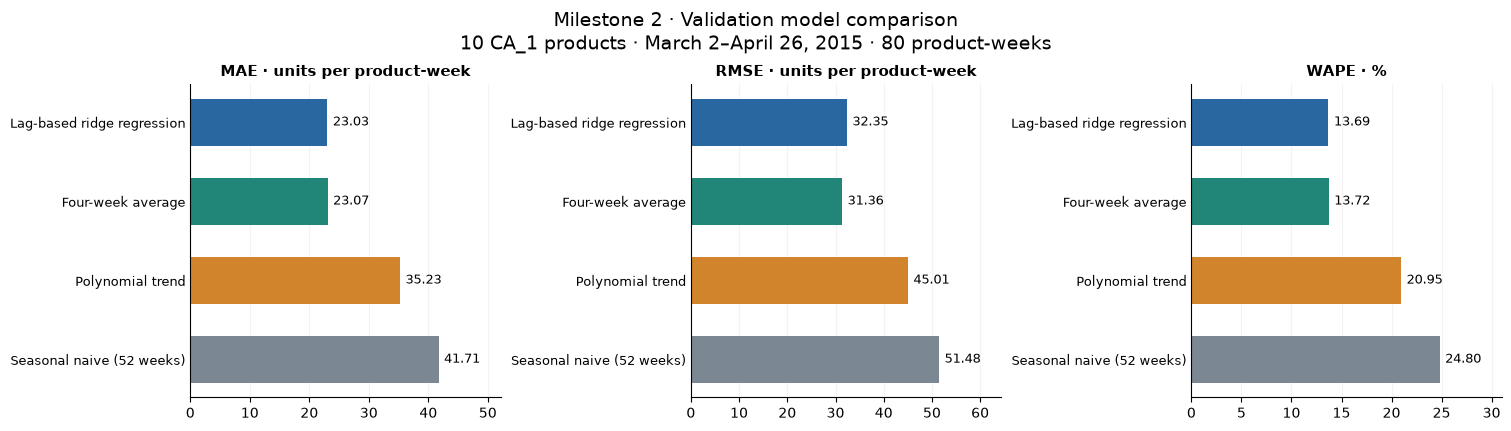

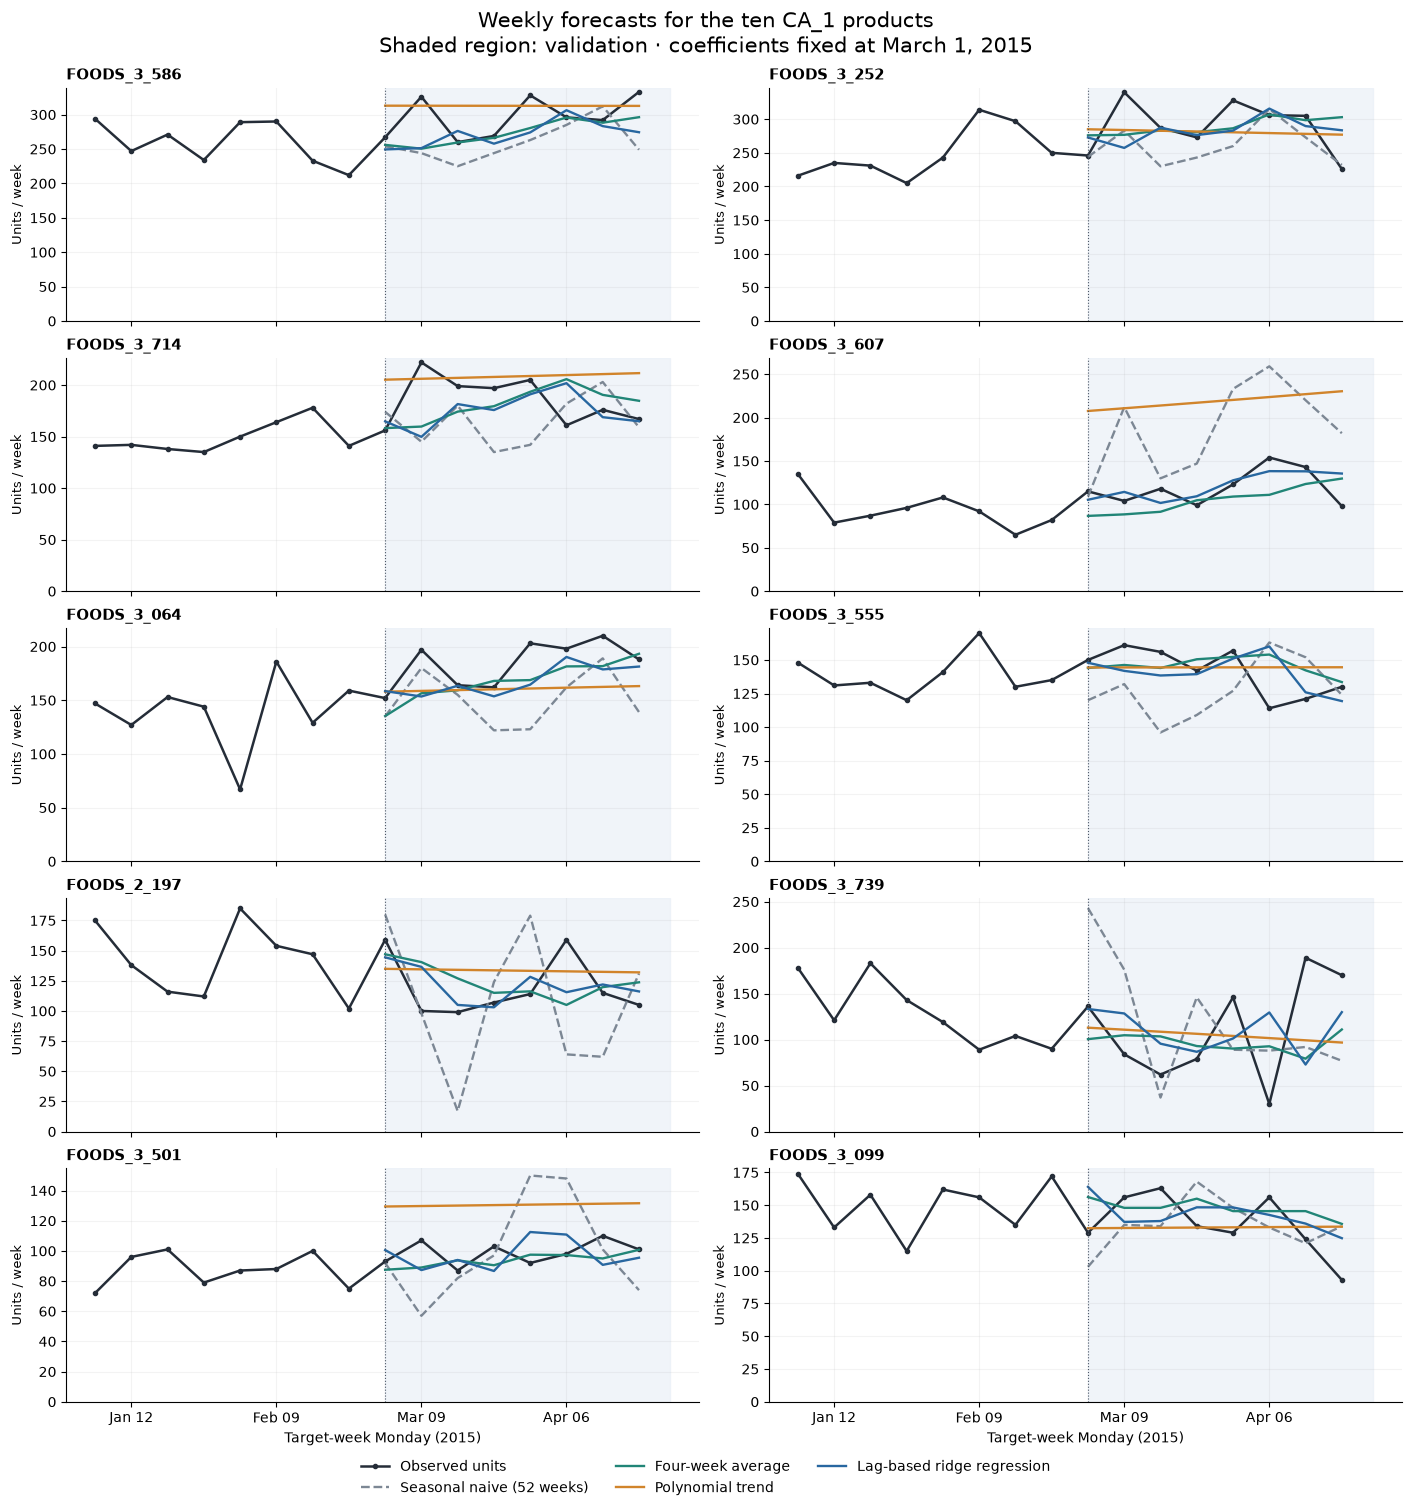

In [12]:
m2_figure_dir = M2_MODEL_DIR / "figures"
m2_figure_dir.mkdir(parents=True, exist_ok=True)

# Compare all methods on exactly the same validation observations.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout="constrained")
labels = m2_comparison.model.map(M2_MODEL_LABELS).tolist()
colors = m2_comparison.model.map(M2_MODEL_COLORS).tolist()
for ax, metric, title in zip(axes, ["MAE", "RMSE", "WAPE_pct"],
                            ["MAE · units per product-week", "RMSE · units per product-week", "WAPE · %"]):
    bars = ax.barh(labels, m2_comparison[metric], color=colors, height=0.6)
    ax.invert_yaxis()
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)
    ax.set_xlim(0, float(m2_comparison[metric].max()) * 1.25)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=9)
fig.suptitle("Milestone 2 · Validation model comparison\n10 CA_1 products · March 2–April 26, 2015 · 80 product-weeks", fontsize=14)
fig.savefig(m2_figure_dir / "validation_model_comparison.png", dpi=170, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

# Show training context and the weekly forecasts for every selected product.
fig, axes = plt.subplots(5, 2, figsize=(14, 15), sharex=True, layout="constrained")
first_validation = m2_validation.week_start.min()
history_start = first_validation - pd.Timedelta(weeks=8)
context = pd.concat([m2_train, m2_validation], ignore_index=True)
for ax, item in zip(axes.flat, M2_EXPERIMENT["item_ids"]):
    actual = context[context.item_id.eq(item) & context.week_start.ge(history_start)]
    ax.axvspan(first_validation, m2_validation.week_end.max(), color="#E9EFF6", alpha=0.65)
    ax.plot(actual.week_start, actual.target_units, color="#252D38", marker="o",
            markersize=3, linewidth=1.8, label="Observed units")
    for model in M2_MODEL_LABELS:
        rows = m2_predictions[m2_predictions.item_id.eq(item) & m2_predictions.model.eq(model)]
        ax.plot(rows.week_start, rows.predicted_units, color=M2_MODEL_COLORS[model],
                linewidth=1.7, linestyle="--" if model == "seasonal_naive_52w" else "-",
                label=M2_MODEL_LABELS[model])
    ax.axvline(first_validation, color="#4B5563", linewidth=0.8, linestyle=":")
    ax.set_title(item, fontsize=11, fontweight="bold", loc="left")
    ax.set_ylabel("Units / week", fontsize=9)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3, fontsize=10, frameon=False)
fig.suptitle("Weekly forecasts for the ten CA_1 products\nShaded region: validation · coefficients fixed at March 1, 2015", fontsize=15)
for ax in axes[-1]:
    ax.set_xlabel("Target-week Monday (2015)")
fig.savefig(m2_figure_dir / "validation_forecasts_by_product.png", dpi=170, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)


### 4.6 Verify timing, numerical fits, and predictions

Reconcile both benchmarks directly to daily sales. Check the polynomial against
NumPy's independent polynomial fitter and ridge against the regularized normal
equations. Predictions must work without target or split columns. Replace every
test target and numeric input with an impossible negative sentinel, repeat tuning
and fitting, and require identical fitted parameters and validation predictions.
The earlier 19 checks continue to verify feature timing and raw-source integrity.


In [13]:
m2_model_checks = []
def m2_model_check(name, condition, detail):
    assert bool(condition), name
    m2_model_checks.append({"check": name, "passed": True, "detail": detail})

m2_model_check("Common validation coverage",
    len(m2_predictions) == 320
    and not m2_predictions.duplicated(["model", "store_id", "item_id", "week_start"]).any()
    and m2_predictions.groupby(["model", "item_id"]).size().eq(8).all(),
    "Four methods each predict the same 80 product-weeks; no rows are omitted.")
m2_model_check("Training and tuning precede validation",
    m2_cv_folds.heldout_end.le(pd.Timestamp(M2_EXPERIMENT["train_end"])).all()
    and m2_cv_folds.fit_end.lt(m2_cv_folds.heldout_start).all()
    and all(state.get("fit_last_target_day", M2_EXPERIMENT["train_end"]) == M2_EXPERIMENT["train_end"]
            for state in m2_fitted_models.values()),
    "Preprocessing and coefficients use only training observations; CV folds keep whole weeks together.")
m2_model_check("Finite nonnegative point forecasts",
    np.isfinite(m2_predictions.predicted_units).all() and m2_predictions.predicted_units.ge(0).all(),
    "Forecasts stay fractional; any negative raw predictions are recorded and clipped at zero.")

# Reconcile both benchmarks directly to daily observations, rather than to the lag columns.
m2_daily_for_baselines = {
    item: rows.set_index("date").units.sort_index()
    for item, rows in m2_selected_daily.groupby("item_id")
}
m2_expected_seasonal, m2_expected_average = [], []
for row in m2_validation.itertuples(index=False):
    daily = m2_daily_for_baselines[row.item_id]
    annual = daily.loc[row.week_start-pd.Timedelta(weeks=52):row.week_end-pd.Timedelta(weeks=52)]
    recent = daily.loc[row.forecast_origin-pd.Timedelta(days=27):row.forecast_origin]
    assert len(annual) == 7 and len(recent) == 28
    m2_expected_seasonal.append(float(annual.sum()))
    m2_expected_average.append(float(recent.sum())/4)
m2_model_check("Benchmarks match raw daily history",
    np.allclose(m2_predict(m2_fitted_models["seasonal_naive_52w"], m2_validation), m2_expected_seasonal)
    and np.allclose(m2_predict(m2_fitted_models["moving_average_4w"], m2_validation), m2_expected_average),
    "All seasonal forecasts match sales 52 weeks earlier; all averages match the preceding 28 days / 4.")

# Check our augmented ridge solve against an independent normal-equation solve.
m2_ridge_state = m2_fitted_models["lag_ridge"]
m2_design = m2_ridge_design(m2_train, m2_ridge_state)
m2_penalty = np.eye(m2_design.shape[1]); m2_penalty[0, 0] = 0
m2_reference_coefficients = np.linalg.solve(
    m2_design.T @ m2_design + m2_ridge_state["alpha"] * m2_penalty,
    m2_design.T @ m2_train.target_units.to_numpy(float),
)
m2_model_check("Ridge agrees with independent solver",
    np.allclose(m2_reference_coefficients, m2_ridge_state["coefficients"], rtol=1e-8, atol=1e-8),
    "The augmented least-squares solution matches the regularized normal equations; intercept is unpenalized.")

# NumPy Polynomial.fit uses a different time normalization from our explicit design matrix.
m2_polynomial_state = m2_fitted_models["polynomial_trend"]
m2_polynomial_reference = np.empty(len(m2_validation))
for item, product in m2_polynomial_state["products"].items():
    rows = m2_train[m2_train.item_id.eq(item)]
    positions = np.flatnonzero(m2_validation.item_id.eq(item).to_numpy())
    curve = np.polynomial.Polynomial.fit(
        m2_week_index(rows, m2_polynomial_state["time_origin"]), rows.target_units,
        deg=m2_polynomial_state["degree"],
    )
    m2_polynomial_reference[positions] = curve(
        m2_week_index(m2_validation.iloc[positions], m2_polynomial_state["time_origin"])
    )
m2_model_check("Polynomial agrees with independent fit",
    np.allclose(m2_polynomial_reference, m2_predict_raw(m2_polynomial_state, m2_validation), rtol=1e-9, atol=1e-8),
    "The ten curves agree with NumPy Polynomial.fit, despite using a different scaled basis.")

# Predictions must work with labels and split flags entirely absent.
m2_prediction_inputs = m2_validation.drop(columns=["target_units", "split"])
m2_model_check("Prediction does not read labels or split flags",
    all(np.array_equal(m2_predict(state, m2_prediction_inputs), m2_predict(state, m2_validation))
        for state in m2_fitted_models.values()),
    "Predicting from the input-only frame gives exactly the same forecasts.")

# Replace test values with an impossible negative sentinel, then repeat tuning and training.
m2_poisoned_panel = m2_model_panel.copy()
m2_test_mask = m2_poisoned_panel.split.eq("test")
for field in M2_NUMERIC_FEATURES + ["target_units"]:
    m2_poisoned_panel.loc[m2_test_mask, field] = -1
m2_poison_train = m2_training_rows(m2_poisoned_panel)
_, _, m2_poison_tuning, m2_poison_specs = m2_tune_models(m2_poison_train)
pd.testing.assert_frame_equal(m2_poison_tuning, m2_tuning_summary, check_exact=True)
m2_poison_states = {model: {"model": model} for model in ["seasonal_naive_52w", "moving_average_4w"]}
for spec in m2_poison_specs:
    m2_poison_states[spec["model"]] = m2_fit_model(m2_poison_train, spec)
assert json.dumps(m2_poison_states, sort_keys=True) == json.dumps(m2_fitted_models, sort_keys=True)
m2_poison_validation = m2_poisoned_panel.loc[m2_poisoned_panel.split.eq("validation")].copy()
m2_poison_validation = m2_poison_validation.sort_values(["week_start", "item_id"]).reset_index(drop=True)
pd.testing.assert_frame_equal(
    m2_prediction_table(m2_poison_states, m2_poison_validation), m2_predictions, check_exact=True
)
m2_model_check("Test perturbations cannot affect model selection", True,
    "Changing every test target/input leaves tuning, fitted parameters, and validation forecasts exactly unchanged.")

# Recompute aggregate errors from the long prediction table, including WAPE's denominator.
for model, rows in m2_predictions.groupby("model"):
    score = m2_comparison.set_index("model").loc[model]
    assert np.isclose(score.MAE, rows.absolute_error.sum()/len(rows))
    assert np.isclose(score.RMSE, np.sqrt(rows.squared_error.sum()/len(rows)))
    assert np.isclose(score.WAPE_pct, 100*rows.absolute_error.sum()/rows.actual_units.abs().sum())
m2_model_check("Exported comparison reconciles to row errors", True,
    "MAE, RMSE, and WAPE agree with independently aggregated per-observation errors.")

display(pd.DataFrame(m2_model_checks))


,check,passed,detail
0,Common validation coverage,True,Four methods each predict the same 80 product-weeks; no rows are omitted.
1,Training and tuning precede validation,True,Preprocessing and coefficients use only training observations; CV folds keep whole weeks together.
2,Finite nonnegative point forecasts,True,Forecasts stay fractional; any negative raw predictions are recorded and clipped at zero.
3,Benchmarks match raw daily history,True,All seasonal forecasts match sales 52 weeks earlier; all averages match the preceding 28 days / 4.
4,Ridge agrees with independent solver,True,The augmented least-squares solution matches the regularized normal equations; intercept is unpe...
5,Polynomial agrees with independent fit,True,"The ten curves agree with NumPy Polynomial.fit, despite using a different scaled basis."
6,Prediction does not read labels or split flags,True,Predicting from the input-only frame gives exactly the same forecasts.
7,Test perturbations cannot affect model selection,True,"Changing every test target/input leaves tuning, fitted parameters, and validation forecasts exac..."
8,Exported comparison reconciles to row errors,True,"MAE, RMSE, and WAPE agree with independently aggregated per-observation errors."


### 4.7 Save the comparison and modeling handoff

Export candidate scores, validation forecasts, overall/product/quarter metrics,
figures, fitted parameters, input definitions, and verification results together
under `outputs/milestone2/models/`. Verify that the saved parameters reproduce
the forecasts. The generated discussion reports the actual ranking and any
tradeoff between MAE and RMSE.

Section 5 freezes the model choices and validation-only interval calibration
settings before scoring the held-out test period. Test interval coverage and
uncertainty plots remain Part 5.


In [14]:
M2_MODEL_DIR.mkdir(parents=True, exist_ok=True)
m2_model_tables = {
    "cv_folds.csv": m2_cv_folds,
    "cv_candidate_scores.csv": m2_cv_scores,
    "hyperparameter_comparison.csv": m2_tuning_summary,
    "validation_predictions.csv": m2_predictions,
    "validation_metrics.csv": m2_comparison,
    "validation_metrics_by_product.csv": m2_product_metrics,
    "validation_metrics_by_quarter.csv": m2_quarter_metrics,
}
for filename, table in m2_model_tables.items():
    table.to_csv(M2_MODEL_DIR / filename, index=False, date_format="%Y-%m-%d")
(M2_MODEL_DIR / "fitted_models.json").write_text(
    json.dumps(m2_fitted_models, indent=2, allow_nan=False)+'\n', encoding="utf-8"
)

# These artifacts are reusable without refitting; verify their persisted form now.
m2_loaded_models = json.loads((M2_MODEL_DIR / "fitted_models.json").read_text())
assert all(np.array_equal(m2_predict(state, m2_validation), m2_predict(m2_loaded_models[model], m2_validation))
           for model, state in m2_fitted_models.items())
m2_loaded_predictions = pd.read_csv(M2_MODEL_DIR / "validation_predictions.csv")
assert m2_loaded_predictions.model.tolist() == m2_predictions.model.tolist()
assert np.allclose(m2_loaded_predictions.predicted_units, m2_predictions.predicted_units, rtol=1e-12, atol=1e-12)
m2_model_check("Saved models and predictions round-trip", True,
    "Reloaded JSON model states reproduce all forecasts; the CSV preserves prediction values and order.")
m2_training_checks = pd.DataFrame(m2_model_checks)
m2_training_checks.to_csv(M2_MODEL_DIR / "model_training_checks.csv", index=False)

m2_model_feature_roles = pd.DataFrame([
    {"model": "seasonal_naive_52w", "input": "sales_lag_52w", "construction": "Observed weekly units 52 weeks before the target"},
    {"model": "moving_average_4w", "input": "sales_mean_4w", "construction": "Mean of four completed weekly unit totals"},
    {"model": "polynomial_trend", "input": "scaled_calendar_week_index",
     "construction": "Known target Monday minus train_start, divided by seven days; center/scale fitted per product using training rows"},
    {"model": "polynomial_trend", "input": "item_id", "construction": "Select the product's separately fitted polynomial"},
    {"model": "lag_ridge", "input": "item_id", "construction": "Training-only product indicators; first sorted product is the reference"},
] + [{"model": "lag_ridge", "input": feature,
       "construction": "Prepared historical/calendar feature, standardized using training-only mean and population standard deviation"}
      for feature in M2_RIDGE_FEATURES])
m2_model_feature_roles.to_csv(M2_MODEL_DIR / "model_feature_roles.csv", index=False)

m2_best_row = m2_comparison.iloc[0]
m2_average_row = m2_comparison.set_index("model").loc["moving_average_4w"]
m2_best_rmse = m2_comparison.sort_values(["RMSE", "MAE", "model"]).iloc[0]
m2_mean_gain = 100 * (1 - float(m2_best_row.MAE)/float(m2_average_row.MAE))
m2_selection = {
    "primary_metric": "Validation MAE (units per product-week); RMSE breaks ties",
    "selected_model": m2_selected_model,
    "lowest_RMSE_model": str(m2_best_rmse.model),
    "hyperparameters": {spec["model"]: spec for spec in m2_best_specs},
    "tuning_policy": "Three expanding training windows, each followed by eight held-out training weeks; pool 240 errors per candidate",
    "fit_end": M2_EXPERIMENT["train_end"],
    "validation_start": M2_EXPERIMENT["validation_start"],
    "validation_end": M2_EXPERIMENT["validation_end"],
    "validation_observations_per_model": len(m2_validation),
    "coefficient_update_policy": "Coefficients fixed within each CV block and final validation; lag inputs update after observations occur",
    "forecast_policy": "One week ahead; negative fitted-model outputs clipped to zero; no rounding",
    "best_MAE_gain_vs_four_week_average_pct": m2_mean_gain,
    "test_used_for_tuning": False, "test_used_for_model_selection": False, "test_scored": False,
    "prediction_intervals_available": False,
    "checks_passed": bool(m2_training_checks.passed.all()), "training_check_count": len(m2_training_checks),
    "prepared_panel_sha256": m2_sha256(M2_OUTPUT_DIR / "weekly_forecasting_panel.csv"),
    "source_sha256": m2_source_hashes_before,
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "matplotlib": metadata.version("matplotlib")},
}
(M2_MODEL_DIR / "model_selection.json").write_text(json.dumps(m2_selection, indent=2, allow_nan=False)+'\n')

m2_results_table = "| Method | MAE | RMSE | WAPE |\n|---|---:|---:|---:|\n" + "\n".join(
    f"| {row.model_name} | {row.MAE:.2f} | {row.RMSE:.2f} | {row.WAPE_pct:.2f}% |"
    for row in m2_comparison.itertuples(index=False)
)
m2_tradeoff = (
    f"The lowest validation MAE is **{m2_best_row.MAE:.2f}** for **{M2_MODEL_LABELS[m2_selected_model]}**. "
    f"The lowest RMSE is **{m2_best_rmse.RMSE:.2f}** for **{m2_best_rmse.model_name}**. "
    f"The best MAE improves on the four-week average by only **{m2_mean_gain:.2f}%** "
    f"({m2_average_row.MAE-m2_best_row.MAE:.3f} units per product-week). "
    "Treat small differences as a close comparison, not evidence of a reliable advantage across seasons."
)
m2_report = f"""# Part 3 — Train and compare models

The comparison uses the same ten CA_1 products and 80 validation product-weeks, March 2–April 26, 2015. Coefficients are fitted through March 1, 2015. MAE and RMSE are in units per product-week; WAPE is 100 × total absolute error / total observed units. Positive bias means overprediction.

## Methods and tuning

- Seasonal naive: the completed weekly sales total 52 weeks earlier (364 days), an approximation to annual seasonality.
- Four-week average: the mean of the four preceding completed weekly totals.
- Proposed polynomial: a separate least-squares curve over calendar time for each product. Training-only chronological cross-validation selected degree **{m2_polynomial_state['degree']}** from degrees 2 and 3.
- Lag-based ridge regression: pooled regression using all 14 prepared numeric features and product indicators. Cross-validation selected alpha **{m2_ridge_state['alpha']:g}** from 0.1, 1, 10, 100, and 1000. Numeric scaling and product encoding are fitted on the training portion of each fold. The intercept is unpenalized.

Three expanding training folds each hold out the next eight weeks, yielding 240 historical comparisons per candidate. The separate eight-week validation window ranks the four fixed methods by MAE, with RMSE as the tie-breaker. All models make a new one-week-ahead forecast each week; observed earlier weeks may update lag inputs, while fitted coefficients stay fixed during each evaluation block. Forecasts stay fractional; negative raw predictions are retained in the audit table and clipped to zero for scoring.

## Validation results

{m2_results_table}

{m2_tradeoff}

Relative to seasonal naive, the MAE-selected method reduces validation MAE by **{m2_best_row.MAE_reduction_vs_seasonal_pct:.2f}%** and RMSE by **{m2_best_row.RMSE_reduction_vs_seasonal_pct:.2f}%**. These are validation results, not the proposal's final test-year success criterion.

The polynomial curve describes a smooth time trend and does not adapt to recent sales through lag inputs. Its extrapolation can be poor when demand changes or seasonality dominates. Ridge and the moving average use recent observed sales; the validation table determines their ranking without assuming a fitted model must outperform a benchmark.

## Scope and next step

Validation covers only eight spring weeks at one store. Product/quarter tables describe this window; the Q1/Q2 results cover partial quarters, assigned by target Monday. They do not establish full-year performance or statistical significance. The 56-week test period is excluded from all tuning and selection. Part 4 in Section 5 evaluates these fixed models on the test period; see [the test evaluation](../evaluation/README.md). Prediction intervals, coverage, and uncertainty plots remain Part 5.

## Reproduce and reuse

Open [the Milestone 2 notebook](../../../M5_Milestone_2_Demand_Forecasting.ipynb) and run all cells using the project Python 3.15 environment. Part 3 is Section 4. The fitted models use the existing NumPy least-squares solver; no additional packages are needed. The polynomial's derived calendar time index is documented separately from the prepared lag-feature list in `model_feature_roles.csv`. Store, state, category, and department are omitted from ridge because they are constant or already determined by the selected product identifier.

The notebook's `m2_predict(state, input_rows)` reconstructs predictions from `fitted_models.json`, including stored scales and coefficients. Supply the prepared past-only features and target-week calendar fields. No target column is needed for prediction. Part 4 retains these original training-fitted parameters and freezes validation-only calibration settings before test scoring; there is no validation/test refit.

## Files

- `cv_folds.csv`, `cv_candidate_scores.csv`, `hyperparameter_comparison.csv`: chronological tuning evidence.
- `validation_predictions.csv`: all 320 forecasts, actuals, raw forecasts, and errors.
- `validation_metrics.csv`: overall comparison and improvement versus seasonal naive.
- `validation_metrics_by_product.csv`, `validation_metrics_by_quarter.csv`: subgroup results.
- `fitted_models.json`, `model_selection.json`, `model_feature_roles.csv`: reusable parameters, selection policy, and input definitions.
- `model_training_checks.csv`: {len(m2_training_checks)} passing checks, including independent numerical fits and test-data perturbation.
- `figures/validation_model_comparison.png`, `figures/validation_forecasts_by_product.png`: comparison and forecasts for all products.

Method references: [seasonal naive and chronological evaluation](https://otexts.com/fpp3/toolbox.html), [NumPy least squares](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html), and [the ridge objective](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression). The polynomial follows the Group 2 Milestone 1 proposal's least-squares curve-fitting method.
"""
(M2_MODEL_DIR / "README.md").write_text(m2_report, encoding="utf-8")
display(Markdown(m2_report.split("## Reproduce and reuse")[0]))
display(Markdown(f"**Part 3 complete:** four methods compared, {len(m2_training_checks)} training checks passed. Results are in `outputs/milestone2/models/`."))


# Part 3 — Train and compare models

The comparison uses the same ten CA_1 products and 80 validation product-weeks, March 2–April 26, 2015. Coefficients are fitted through March 1, 2015. MAE and RMSE are in units per product-week; WAPE is 100 × total absolute error / total observed units. Positive bias means overprediction.

## Methods and tuning

- Seasonal naive: the completed weekly sales total 52 weeks earlier (364 days), an approximation to annual seasonality.
- Four-week average: the mean of the four preceding completed weekly totals.
- Proposed polynomial: a separate least-squares curve over calendar time for each product. Training-only chronological cross-validation selected degree **2** from degrees 2 and 3.
- Lag-based ridge regression: pooled regression using all 14 prepared numeric features and product indicators. Cross-validation selected alpha **100** from 0.1, 1, 10, 100, and 1000. Numeric scaling and product encoding are fitted on the training portion of each fold. The intercept is unpenalized.

Three expanding training folds each hold out the next eight weeks, yielding 240 historical comparisons per candidate. The separate eight-week validation window ranks the four fixed methods by MAE, with RMSE as the tie-breaker. All models make a new one-week-ahead forecast each week; observed earlier weeks may update lag inputs, while fitted coefficients stay fixed during each evaluation block. Forecasts stay fractional; negative raw predictions are retained in the audit table and clipped to zero for scoring.

## Validation results

| Method | MAE | RMSE | WAPE |
|---|---:|---:|---:|
| Lag-based ridge regression | 23.03 | 32.35 | 13.69% |
| Four-week average | 23.07 | 31.36 | 13.72% |
| Polynomial trend | 35.23 | 45.01 | 20.95% |
| Seasonal naive (52 weeks) | 41.71 | 51.48 | 24.80% |

The lowest validation MAE is **23.03** for **Lag-based ridge regression**. The lowest RMSE is **31.36** for **Four-week average**. The best MAE improves on the four-week average by only **0.17%** (0.040 units per product-week). Treat small differences as a close comparison, not evidence of a reliable advantage across seasons.

Relative to seasonal naive, the MAE-selected method reduces validation MAE by **44.80%** and RMSE by **37.15%**. These are validation results, not the proposal's final test-year success criterion.

The polynomial curve describes a smooth time trend and does not adapt to recent sales through lag inputs. Its extrapolation can be poor when demand changes or seasonality dominates. Ridge and the moving average use recent observed sales; the validation table determines their ranking without assuming a fitted model must outperform a benchmark.

## Scope and next step

Validation covers only eight spring weeks at one store. Product/quarter tables describe this window; the Q1/Q2 results cover partial quarters, assigned by target Monday. They do not establish full-year performance or statistical significance. The 56-week test period is excluded from all tuning and selection. Part 4 in Section 5 evaluates these fixed models on the test period; see [the test evaluation](../evaluation/README.md). Prediction intervals, coverage, and uncertainty plots remain Part 5.



**Part 3 complete:** four methods compared, 10 training checks passed. Results are in `outputs/milestone2/models/`.

<a id="milestone-2-evaluation"></a>

## 5 Evaluate forecasts (Part 4)

### 5.1 Freeze the evaluation and calibration protocol

Evaluate all four methods on the same **560 test observations**: ten products at
CA_1 over 56 Monday–Sunday weeks, **April 27, 2015–May 22, 2016**. Keep the degree-2
polynomial, ridge alpha 100, original training-fitted coefficients, and the
validation-selected ridge model unchanged. There is no refit or reselection
using test outcomes. Earlier observed test sales can supply later lag inputs;
the forecast horizon remains one week.

Before calculating any test errors, save the fitted states and model-selection
record. Operationalize the proposal's 10% improvement target as **at least 10%
lower overall MAE AND RMSE than seasonal naive**, and report each reduction
separately. Assess the validation-selected ridge model as the primary result.
Product/quarter attainment is diagnostic; it need not hold in every subgroup.

Also freeze the settings needed for Part 5 before exposing test performance:
for each model, use the 80 absolute validation residuals to calibrate **80% and
95% intervals**. The half-width is the sorted residual at 1-based rank
`ceil((n+1)*coverage)` (65 and 77). Later intervals use
`[max(0, prediction-width), prediction+width]`. No test residual may change these
choices. This is a pooled empirical calibration baseline: serial dependence,
product heterogeneity, and selection on the same validation window prevent an
exact coverage guarantee. **Constructing test intervals, assessing coverage,
and plotting uncertainty remain Part 5.**


In [15]:
import copy

M2_EVALUATION_DIR = M2_OUTPUT_DIR / "evaluation"
M2_EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
M2_TARGET_REDUCTION_PCT = 10.0
M2_INTERVAL_LEVELS = [0.80, 0.95]

def m2_json_fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()

# Freeze the Part 3 decision and coefficients before reading test errors.
m2_frozen_models = copy.deepcopy(m2_fitted_models)
m2_pretest_selection = copy.deepcopy(m2_selection)
m2_pretest_selected_model = str(m2_selected_model)
assert m2_pretest_selected_model == "lag_ridge"
assert m2_frozen_models["polynomial_trend"]["degree"] == 2
assert m2_frozen_models["lag_ridge"]["alpha"] == 100.0
assert not m2_pretest_selection["test_used_for_tuning"]
assert not m2_pretest_selection["test_used_for_model_selection"]
assert all(s.get("fit_last_target_day", M2_EXPERIMENT["train_end"]) == M2_EXPERIMENT["train_end"]
           for s in m2_frozen_models.values())
m2_frozen_model_fingerprint = m2_json_fingerprint(m2_frozen_models)

# Preparatory calibration for Part 5 uses only the already-scored validation rows.
# With n scores, choose order statistic ceil((n+1)*nominal_coverage), using 1-based ranks.
# These are empirical residual intervals; time dependence and model selection on
# the same validation window mean an exact conformal coverage guarantee is not claimed.
m2_interval_calibration_records = []
for model, rows in m2_predictions.groupby("model", sort=False):
    assert len(rows) == 80 and rows.week_end.max() == pd.Timestamp(M2_EXPERIMENT["validation_end"])
    assert rows.week_start.min() == pd.Timestamp(M2_EXPERIMENT["validation_start"])
    errors = np.sort(np.abs(rows.actual_units.to_numpy(float) - rows.predicted_units.to_numpy(float)))
    for coverage in M2_INTERVAL_LEVELS:
        rank = math.ceil((len(errors)+1)*coverage)
        assert 1 <= rank <= len(errors)
        m2_interval_calibration_records.append({
            "model": model, "nominal_coverage": coverage, "calibration_rows": len(errors),
            "calibration_start": rows.week_start.min(), "calibration_end": rows.week_end.max(),
            "order_statistic_rank": rank, "half_width_units": float(errors[rank-1]),
        })
m2_interval_calibration = pd.DataFrame(m2_interval_calibration_records)
m2_interval_calibration.to_csv(M2_EVALUATION_DIR / "pretest_interval_calibration.csv",
                               index=False, date_format="%Y-%m-%d")
m2_pretest_protocol = {
    "selected_before_test": m2_pretest_selected_model,
    "models": list(M2_MODEL_LABELS),
    "fit_end": M2_EXPERIMENT["train_end"],
    "fit_policy": "Use the original training-fitted coefficients; no refit on validation or test",
    "forecast_policy": "Sequential one-week-ahead forecasts; earlier observed test sales may update later lag inputs",
    "test_start": M2_EXPERIMENT["test_start"], "test_end": M2_EXPERIMENT["test_end"],
    "test_observations_per_model": 560,
    "metrics": ["MAE", "RMSE", "WAPE_pct"],
    "primary_metric": "MAE", "reference_model": "seasonal_naive_52w",
    "target_relative_reduction_pct": M2_TARGET_REDUCTION_PCT,
    "target_rule": "At least 10% lower overall MAE AND RMSE than seasonal naive; report each metric separately",
    "target_scope": "Overall test result for the validation-selected model; product/quarter attainment is diagnostic",
    "quarter_rule": "Assign the entire target week to its Monday's calendar quarter; identify partial quarters",
    "zero_denominator_policy": "WAPE or relative improvement is undefined if its denominator is zero",
    "negative_forecast_policy": "Clip negative forecasts at zero; retain raw values; no rounding",
    "no_test_tuning_or_reselection": True,
    "fitted_models_fingerprint": m2_frozen_model_fingerprint,
    "interval_plan": {
        "status": "Calibrated from validation before test scoring; interval construction, coverage, and plots are Part 5",
        "nominal_levels": M2_INTERVAL_LEVELS,
        "method": "Per-model pooled absolute validation residual order statistics; symmetric widths; lower endpoint clipped to zero",
        "rank_rule": "ceil((n+1)*coverage), 1-based order statistic",
        "calibration_rows_per_model": 80,
        "test_residuals_allowed_for_calibration": False,
        "limitations": "Serial dependence, mixed product scales, and model selection on validation prevent an exact coverage guarantee",
    },
    "interval_calibration_sha256": m2_sha256(M2_EVALUATION_DIR / "pretest_interval_calibration.csv"),
}
for filename, value in {
    "pretest_protocol.json": m2_pretest_protocol,
    "frozen_model_selection.json": m2_pretest_selection,
    "frozen_fitted_models.json": m2_frozen_models,
}.items():
    (M2_EVALUATION_DIR / filename).write_text(json.dumps(value, indent=2, allow_nan=False)+'\n')
display(Markdown(
    "**Protocol fixed before scoring:** retain the Part 3 models and ridge selection; "
    "assess a 10% reduction in both MAE and RMSE against seasonal naive. "
    "Calibration values for later 80%/95% intervals use validation errors only."
))


**Protocol fixed before scoring:** retain the Part 3 models and ridge selection; assess a 10% reduction in both MAE and RMSE against seasonal naive. Calibration values for later 80%/95% intervals use validation errors only.

### 5.2 Score the identical held-out observations

For each model and observation, let $e_i=\hat y_i-y_i$:

- $\mathrm{MAE}=\sum_i |e_i|/n$, in units per product-week.
- $\mathrm{RMSE}=\sqrt{\sum_i e_i^2/n}$, in units per product-week.
- $\mathrm{WAPE}=100\sum_i |e_i|/\sum_i |y_i|$, expressed as a percentage.

Report relative reduction as `100 * (1 - model error / seasonal-naive error)`.
Negative values mean worse performance. WAPE and MAE rank these models
identically because they share the same observations and denominator. An error
ratio with a zero denominator is undefined. Keep every observation, retain raw
forecasts, and apply the predeclared zero clipping without rounding. The test
ranking is descriptive and cannot change the model chosen on validation.


In [16]:
m2_test = m2_model_panel.loc[m2_model_panel.split.eq("test")].copy()
m2_test = m2_test.sort_values(["week_start", "item_id"]).reset_index(drop=True)
assert len(m2_test) == 560 and m2_test.week_start.nunique() == 56
assert m2_test.groupby("item_id").size().eq(56).all()
assert m2_test.groupby("week_start").size().eq(10).all()
assert m2_test.week_start.min() == pd.Timestamp(M2_EXPERIMENT["test_start"])
assert m2_test.week_end.max() == pd.Timestamp(M2_EXPERIMENT["test_end"])
assert m2_test.forecast_origin.add(pd.Timedelta(days=1)).eq(m2_test.week_start).all()
assert m2_test.sales_information_date.le(m2_test.forecast_origin).all()
assert m2_test.price_information_date.le(m2_test.forecast_origin).all()

# Reuse the same prediction and scoring functions used for validation.
m2_test_predictions = m2_prediction_table(m2_frozen_models, m2_test)

def m2_with_baseline_comparison(metrics, group_columns):
    """Attach the matching seasonal benchmark and relative-error reductions."""
    scores = metrics.copy()
    metric_names = ["MAE", "RMSE", "WAPE_pct"]
    reference = scores.loc[scores.model.eq("seasonal_naive_52w"), group_columns+metric_names]
    reference = reference.rename(columns={name: f"seasonal_{name}" for name in metric_names})
    if group_columns:
        scores = scores.merge(reference, on=group_columns, how="left", validate="many_to_one")
    else:
        assert len(reference) == 1
        for name in metric_names:
            scores[f"seasonal_{name}"] = float(reference.iloc[0][f"seasonal_{name}"])
    for metric, label in [("MAE", "MAE"), ("RMSE", "RMSE"), ("WAPE_pct", "WAPE")]:
        baseline = scores[f"seasonal_{metric}"].to_numpy(float)
        ratio = np.full(len(scores), np.nan)
        np.divide(scores[metric].to_numpy(float), baseline, out=ratio, where=baseline > 0)
        scores[f"{label}_reduction_vs_seasonal_pct"] = 100*(1-ratio)
    valid = scores.seasonal_MAE.gt(0) & scores.seasonal_RMSE.gt(0)
    scores["target_assessable"] = valid
    for metric in ["MAE", "RMSE"]:
        passed = scores[f"{metric}_reduction_vs_seasonal_pct"].ge(M2_TARGET_REDUCTION_PCT)
        scores[f"meets_{metric}_target"] = passed.astype("boolean").where(valid, pd.NA)
    scores["meets_both_targets"] = scores.meets_MAE_target & scores.meets_RMSE_target
    scores["selected_before_test"] = scores.model.eq(m2_pretest_selected_model)
    return scores

m2_test_metrics = m2_with_baseline_comparison(m2_group_metrics(m2_test_predictions, ["model"]), [])
m2_test_metrics = m2_test_metrics.sort_values(["MAE", "RMSE", "model"]).reset_index(drop=True)
m2_test_metrics.insert(0, "test_MAE_rank", np.arange(1, len(m2_test_metrics)+1))
m2_test_metrics.insert(2, "model_name", m2_test_metrics.model.map(M2_MODEL_LABELS))
m2_test_target_assessment = m2_test_metrics[[
    "model", "model_name", "selected_before_test", "MAE", "RMSE", "WAPE_pct",
    "MAE_reduction_vs_seasonal_pct", "RMSE_reduction_vs_seasonal_pct", "WAPE_reduction_vs_seasonal_pct",
    "target_assessable", "meets_MAE_target", "meets_RMSE_target", "meets_both_targets",
]].copy()
m2_selected_test_result = m2_test_metrics.set_index("model").loc[m2_pretest_selected_model]

with pd.option_context("display.max_columns", None, "display.width", 180):
    display(m2_test_metrics[["test_MAE_rank", "model_name", "selected_before_test", "observations",
                             "MAE", "RMSE", "WAPE_pct", "bias_units", "clipped_predictions"]])
    display(m2_test_target_assessment[["model_name", "MAE_reduction_vs_seasonal_pct",
                                     "RMSE_reduction_vs_seasonal_pct", "meets_both_targets"]])
display(Markdown(
    "**Evaluation covers 560 identical test observations per method (2,240 forecasts).** "
    "The descriptive test ranking does not change the model selected on validation: "
    f"**{M2_MODEL_LABELS[m2_pretest_selected_model]}**."
))


,test_MAE_rank,model_name,selected_before_test,observations,MAE,RMSE,WAPE_pct,bias_units,clipped_predictions
0,1,Lag-based ridge regression,True,560,25.118,36.512,15.431,0.895,0
1,2,Four-week average,False,560,26.987,41.710,16.579,0.183,0
2,3,Seasonal naive (52 weeks),False,560,52.236,67.844,32.090,18.814,0
3,4,Polynomial trend,False,560,71.203,106.001,43.742,26.726,26


,model_name,MAE_reduction_vs_seasonal_pct,RMSE_reduction_vs_seasonal_pct,meets_both_targets
0,Lag-based ridge regression,51.914,46.182,True
1,Four-week average,48.337,38.520,True
2,Seasonal naive (52 weeks),0.000,0.000,False
3,Polynomial trend,-36.312,-56.243,False


**Evaluation covers 560 identical test observations per method (2,240 forecasts).** The descriptive test ranking does not change the model selected on validation: **Lag-based ridge regression**.

### 5.3 Compare products and calendar quarters

Each product contributes **56 observations per method**. Quarter tables use the
quarter of target Monday and keep each seven-day target intact. The first and
last test groups (**2015Q2 and 2016Q2**) are partial quarters; do not present them
as complete-quarter estimates. Export MAE, RMSE, WAPE, matched seasonal-baseline
reductions, and the two-metric target assessment for every model by product,
by quarter, and by product within quarter.

The WAPE pivots show all four methods together, followed by the selected ridge
model's complete metric tables. The CSVs retain all metrics for all methods.
The overall result pools errors and volume; it does not average subgroup RMSE
or subgroup percentage errors.


In [17]:
m2_test_product_metrics = m2_with_baseline_comparison(
    m2_group_metrics(m2_test_predictions, ["model", "item_id"]), ["item_id"]
)
m2_test_quarter_metrics = m2_with_baseline_comparison(
    m2_group_metrics(m2_test_predictions, ["model", "target_quarter"]), ["target_quarter"]
)
m2_test_product_quarter_metrics = m2_with_baseline_comparison(
    m2_group_metrics(m2_test_predictions, ["model", "item_id", "target_quarter"]),
    ["item_id", "target_quarter"],
)

m2_test_week_calendar = m2_test[["week_start", "week_end", "target_quarter"]].drop_duplicates()
m2_quarter_coverage_rows = []
for quarter, weeks in m2_test_week_calendar.groupby("target_quarter", sort=True):
    period = pd.Period(quarter, freq="Q")
    mondays = pd.date_range(period.start_time, period.end_time.normalize(), freq="W-MON")
    m2_quarter_coverage_rows.append({
        "target_quarter": quarter, "test_weeks": len(weeks), "product_weeks": len(weeks)*10,
        "expected_Mondays_in_quarter": len(mondays), "partial_quarter": len(weeks) != len(mondays),
        "first_target_Monday": weeks.week_start.min(), "last_target_Sunday": weeks.week_end.max(),
    })
m2_test_quarter_coverage = pd.DataFrame(m2_quarter_coverage_rows)
for name in ["m2_test_quarter_metrics", "m2_test_product_quarter_metrics"]:
    globals()[name] = globals()[name].merge(
        m2_test_quarter_coverage[["target_quarter", "expected_Mondays_in_quarter", "partial_quarter"]],
        on="target_quarter", how="left", validate="many_to_one",
    )

m2_selected_product_results = m2_test_product_metrics[
    m2_test_product_metrics.selected_before_test
].set_index("item_id").reindex(M2_EXPERIMENT["item_ids"]).reset_index()
m2_selected_quarter_results = m2_test_quarter_metrics[
    m2_test_quarter_metrics.selected_before_test
].sort_values("target_quarter").reset_index(drop=True)

display(Markdown("**WAPE by product (%)** — all methods use the same 56 weeks for each product."))
display(m2_test_product_metrics.pivot(index="item_id", columns="model", values="WAPE_pct")
        .reindex(M2_EXPERIMENT["item_ids"]).rename(columns=M2_MODEL_LABELS))
display(Markdown("**Quarter coverage** — whole weeks belong to the quarter of target Monday."))
display(m2_test_quarter_coverage)
display(Markdown("**WAPE by quarter (%)** — first and last quarters cover only part of the quarter."))
display(m2_test_quarter_metrics.pivot(index="target_quarter", columns="model", values="WAPE_pct")
        .rename(columns=M2_MODEL_LABELS))
with pd.option_context("display.max_columns", None):
    display(m2_selected_product_results[["item_id", "MAE", "RMSE", "WAPE_pct",
                                         "MAE_reduction_vs_seasonal_pct", "RMSE_reduction_vs_seasonal_pct",
                                         "meets_both_targets"]])
    display(m2_selected_quarter_results[["target_quarter", "partial_quarter", "observations", "MAE", "RMSE",
                                         "WAPE_pct", "MAE_reduction_vs_seasonal_pct",
                                         "RMSE_reduction_vs_seasonal_pct", "meets_both_targets"]])


**WAPE by product (%)** — all methods use the same 56 weeks for each product.

model,Lag-based ridge regression,Four-week average,Polynomial trend,Seasonal naive (52 weeks)
item_id,,,,
FOODS_3_586,9.064,10.458,17.157,18.257
FOODS_3_252,11.111,11.200,18.007,17.818
FOODS_3_714,12.119,13.087,55.405,26.962
FOODS_3_607,23.015,20.868,316.968,88.356
FOODS_3_064,11.809,11.921,19.569,25.620
FOODS_3_555,9.987,11.429,16.614,17.927
FOODS_2_197,14.471,17.328,18.339,30.168
FOODS_3_739,27.204,31.884,82.092,68.687
FOODS_3_501,38.972,42.300,45.718,63.781


**Quarter coverage** — whole weeks belong to the quarter of target Monday.

,target_quarter,test_weeks,product_weeks,expected_Mondays_in_quarter,partial_quarter,first_target_Monday,last_target_Sunday
0,2015Q2,10,100,13,True,2015-04-27,2015-07-05
1,2015Q3,13,130,13,False,2015-07-06,2015-10-04
2,2015Q4,13,130,13,False,2015-10-05,2016-01-03
3,2016Q1,13,130,13,False,2016-01-04,2016-04-03
4,2016Q2,7,70,13,True,2016-04-04,2016-05-22


**WAPE by quarter (%)** — first and last quarters cover only part of the quarter.

model,Lag-based ridge regression,Four-week average,Polynomial trend,Seasonal naive (52 weeks)
target_quarter,,,,
2015Q2,15.626,15.694,32.879,38.303
2015Q3,17.063,19.103,38.373,32.411
2015Q4,15.656,16.761,43.904,33.359
2016Q1,15.166,16.843,54.366,27.566
2016Q2,11.903,12.090,52.867,27.381


,item_id,MAE,RMSE,WAPE_pct,MAE_reduction_vs_seasonal_pct,RMSE_reduction_vs_seasonal_pct,meets_both_targets
0,FOODS_3_586,27.412,36.688,9.064,50.354,45.607,True
1,FOODS_3_252,30.100,38.570,11.111,37.641,36.025,True
2,FOODS_3_714,19.215,25.094,12.119,55.052,50.214,True
3,FOODS_3_607,19.271,24.626,23.015,73.951,72.677,True
4,FOODS_3_064,23.475,30.786,11.809,53.906,51.764,True
5,FOODS_3_555,12.764,16.831,9.987,44.287,40.198,True
6,FOODS_2_197,17.389,22.449,14.471,52.031,50.106,True
7,FOODS_3_739,29.570,43.970,27.204,60.394,50.814,True
8,FOODS_3_501,52.898,70.413,38.972,38.897,32.042,True
9,FOODS_3_099,19.085,25.204,15.773,38.078,36.250,True


,target_quarter,partial_quarter,observations,MAE,RMSE,WAPE_pct,MAE_reduction_vs_seasonal_pct,RMSE_reduction_vs_seasonal_pct,meets_both_targets
0,2015Q2,True,100,27.492,38.772,15.626,59.204,55.318,True
1,2015Q3,False,130,30.060,44.516,17.063,47.355,40.510,True
2,2015Q4,False,130,23.831,36.142,15.656,53.067,42.489,True
3,2016Q1,False,130,22.751,30.739,15.166,44.983,41.061,True
4,2016Q2,True,70,19.332,25.629,11.903,56.528,55.262,True


### 5.4 Visualize test error comparisons

Compare MAE, RMSE, and WAPE across the four fixed methods, then examine quarterly
WAPE. The asterisks identify partial quarters. These plots summarize point-forecast
errors; actual-versus-predicted test trajectories with intervals follow in Part 5.


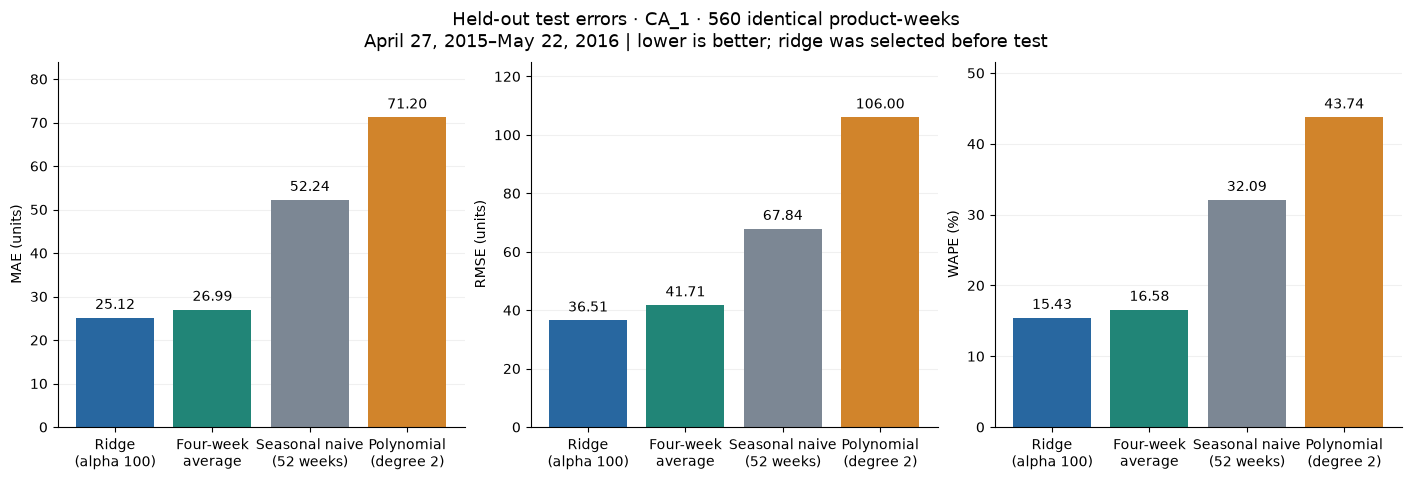

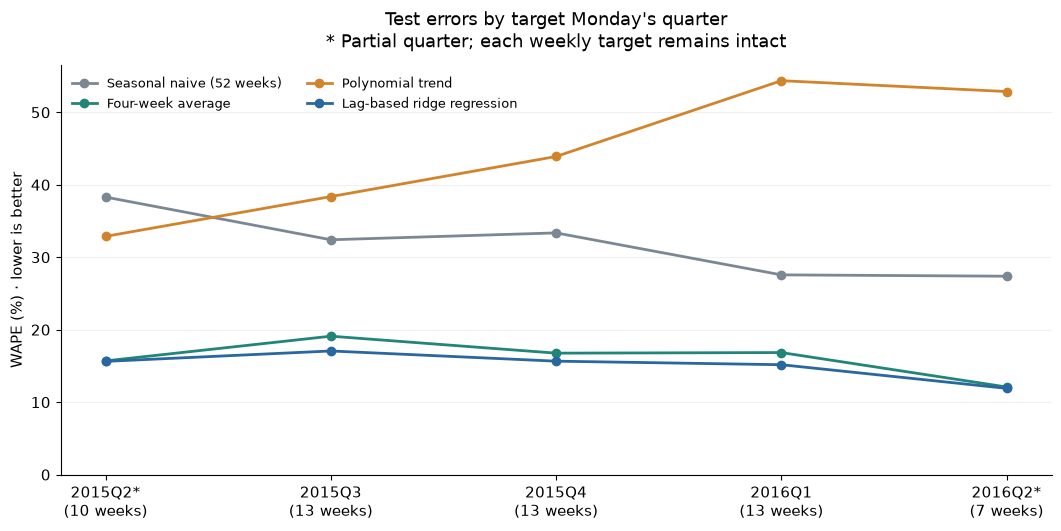

In [18]:
M2_EVALUATION_FIGURES = M2_EVALUATION_DIR / "figures"
M2_EVALUATION_FIGURES.mkdir(exist_ok=True)
m2_test_plot_order = m2_test_metrics.model.tolist()
m2_short_labels = {
    "seasonal_naive_52w": "Seasonal naive\n(52 weeks)",
    "moving_average_4w": "Four-week\naverage",
    "polynomial_trend": "Polynomial\n(degree 2)",
    "lag_ridge": "Ridge\n(alpha 100)",
}
with plt.rc_context({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.7), layout="constrained")
    for ax, metric, label in zip(axes, ["MAE", "RMSE", "WAPE_pct"],
                                 ["MAE (units)", "RMSE (units)", "WAPE (%)"]):
        values = m2_test_metrics.set_index("model").loc[m2_test_plot_order, metric]
        bars = ax.bar(np.arange(4), values, color=[M2_MODEL_COLORS[m] for m in m2_test_plot_order])
        ax.bar_label(bars, labels=[f"{value:.2f}" for value in values], padding=4, fontsize=10)
        ax.set_xticks(np.arange(4), [m2_short_labels[m] for m in m2_test_plot_order])
        ax.set_ylim(0, float(values.max())*1.18)
        ax.set_ylabel(label)
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.18)
    fig.suptitle("Held-out test errors · CA_1 · 560 identical product-weeks\n"
                 "April 27, 2015–May 22, 2016 | lower is better; ridge was selected before test", fontsize=13)
    fig.savefig(M2_EVALUATION_FIGURES / "test_model_comparison.png", dpi=180)
    plt.show()
    plt.close(fig)

with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    fig, ax = plt.subplots(figsize=(10.5, 5.2), layout="constrained")
    quarters = m2_test_quarter_coverage.target_quarter.tolist()
    for model in M2_MODEL_LABELS:
        values = m2_test_quarter_metrics.query("model == @model").set_index("target_quarter")
        ax.plot(np.arange(len(quarters)), values.loc[quarters, "WAPE_pct"], marker="o",
                color=M2_MODEL_COLORS[model], label=M2_MODEL_LABELS[model], linewidth=2)
    tick_labels = [f"{row.target_quarter}{'*' if row.partial_quarter else ''}\n({row.test_weeks} weeks)"
                   for row in m2_test_quarter_coverage.itertuples(index=False)]
    ax.set_xticks(np.arange(len(quarters)), tick_labels)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("WAPE (%) · lower is better")
    ax.grid(axis="y", alpha=0.18)
    ax.legend(loc="upper left", ncol=2, frameon=False, fontsize=9)
    ax.set_title("Test errors by target Monday's quarter\n* Partial quarter; each weekly target remains intact", pad=13)
    fig.savefig(M2_EVALUATION_FIGURES / "test_WAPE_by_quarter.png", dpi=180)
    plt.show()
    plt.close(fig)


### 5.5 Verify the evaluation

Check identical keys and actual values for all methods, unchanged fitted states
and selection, input-only prediction, and raw-daily reconciliation of targets
and both benchmarks. Independently recompute every metric table, reconstruct
pooled scores from subgroup error sums, and validate week/quarter coverage and
the 10% rule. Verify that the saved calibration widths still use validation only.
The export cell additionally checks saved CSVs and frozen model states.


In [19]:
m2_evaluation_checks = []
def m2_evaluation_check(name, condition, detail):
    assert bool(condition), name
    m2_evaluation_checks.append({"check": name, "passed": True, "detail": detail})

m2_expected_test_keys = m2_test[M2_MODEL_KEYS + ["target_quarter", "target_units"]].rename(
    columns={"target_units": "actual_units"}
).reset_index(drop=True)
for model, rows in m2_test_predictions.groupby("model", sort=False):
    pd.testing.assert_frame_equal(rows[m2_expected_test_keys.columns].reset_index(drop=True),
                                  m2_expected_test_keys, check_exact=True)
m2_evaluation_check("Identical test observations for all methods",
    len(m2_test_predictions) == 2240
    and set(m2_test_predictions.model) == set(M2_MODEL_LABELS)
    and not m2_test_predictions.duplicated(["model"]+M2_MODEL_KEYS).any(),
    "Four methods each use the same 560 keys and actual totals; no missing or duplicated predictions.")

m2_evaluation_check("Original fitted models and validation choice preserved",
    m2_json_fingerprint(m2_fitted_models) == m2_frozen_model_fingerprint
    and m2_json_fingerprint(m2_frozen_models) == m2_frozen_model_fingerprint
    and m2_selected_model == m2_pretest_selected_model == m2_selection["selected_model"]
    and all(s.get("fit_last_target_day", M2_EXPERIMENT["train_end"]) == M2_EXPERIMENT["train_end"]
            for s in m2_frozen_models.values()),
    "No validation/test refit, hyperparameter change, or model reselection occurs after test scoring.")

m2_changed_test_labels = m2_test.copy()
m2_changed_test_labels["target_units"] = -12345
m2_input_only_test = m2_test.drop(columns=["target_units", "split"])
m2_evaluation_check("Test labels cannot enter prediction",
    all(np.array_equal(m2_predict(s, m2_test), m2_predict(s, m2_changed_test_labels))
        and np.array_equal(m2_predict(s, m2_test), m2_predict(s, m2_input_only_test))
        for s in m2_frozen_models.values()),
    "Replacing all test target labels or removing labels/split flags leaves forecasts exactly unchanged.")

m2_expected_test_actual, m2_expected_test_seasonal, m2_expected_test_average = [], [], []
for row in m2_test.itertuples(index=False):
    daily = m2_daily_for_baselines[row.item_id]
    actual = daily.loc[row.week_start:row.week_end]
    annual = daily.loc[row.week_start-pd.Timedelta(weeks=52):row.week_end-pd.Timedelta(weeks=52)]
    recent = daily.loc[row.forecast_origin-pd.Timedelta(days=27):row.forecast_origin]
    assert len(actual) == len(annual) == 7 and len(recent) == 28
    m2_expected_test_actual.append(float(actual.sum()))
    m2_expected_test_seasonal.append(float(annual.sum()))
    m2_expected_test_average.append(float(recent.sum())/4)
m2_evaluation_check("Test targets and benchmarks match raw daily sales",
    np.array_equal(m2_test.target_units, m2_expected_test_actual)
    and np.array_equal(m2_predict(m2_frozen_models["seasonal_naive_52w"], m2_test), m2_expected_test_seasonal)
    and np.array_equal(m2_predict(m2_frozen_models["moving_average_4w"], m2_test), m2_expected_test_average),
    "All 560 targets, annual seasonal references, and preceding 28-day averages reconcile independently.")

m2_evaluation_check("Forecasts are finite and nonnegative",
    np.isfinite(m2_test_predictions[["raw_prediction", "predicted_units"]]).all().all()
    and m2_test_predictions.predicted_units.ge(0).all()
    and np.array_equal(m2_test_predictions.predicted_units,
                       np.maximum(m2_test_predictions.raw_prediction, 0)),
    "Raw values are retained; scored forecasts apply only zero clipping, without rounding or dropping rows.")

# Independently check every exported aggregate against its individual forecast errors.
for table, grouping in [
    (m2_test_metrics, ["model"]),
    (m2_test_product_metrics, ["model", "item_id"]),
    (m2_test_quarter_metrics, ["model", "target_quarter"]),
    (m2_test_product_quarter_metrics, ["model", "item_id", "target_quarter"]),
]:
    reference = table.set_index(grouping)
    for key, rows in m2_test_predictions.groupby(grouping, sort=False):
        lookup = key[0] if len(grouping) == 1 and isinstance(key, tuple) else key
        score = reference.loc[lookup]
        error = rows.predicted_units.to_numpy(float) - rows.actual_units.to_numpy(float)
        assert score.observations == len(rows)
        assert np.isclose(score.MAE, sum(abs(error))/len(error))
        assert np.isclose(score.RMSE, math.sqrt(sum(error**2)/len(error)))
        denominator = sum(abs(rows.actual_units.to_numpy(float)))
        expected_wape = 100*sum(abs(error))/denominator if denominator else np.nan
        assert np.isclose(score.WAPE_pct, expected_wape, equal_nan=True)
m2_evaluation_check("All metric tables reconcile to individual errors", True,
    "Overall, product, quarter, and product-quarter MAE/RMSE/WAPE independently match their forecast rows.")

for table in [m2_test_product_metrics, m2_test_quarter_metrics, m2_test_product_quarter_metrics]:
    for model, groups in table.groupby("model"):
        overall = m2_test_metrics.set_index("model").loc[model]
        n = groups.observations.sum()
        sum_absolute_error = (groups.MAE*groups.observations).sum()
        sum_squared_error = ((groups.RMSE**2)*groups.observations).sum()
        assert n == 560 and np.isclose(groups.actual_units.sum(), overall.actual_units)
        assert np.isclose(sum_absolute_error/n, overall.MAE)
        assert np.isclose(np.sqrt(sum_squared_error/n), overall.RMSE)
        assert np.isclose(100*sum_absolute_error/groups.actual_units.sum(), overall.WAPE_pct)
m2_evaluation_check("Subgroup totals reconstruct pooled metrics", True,
    "Pool error sums and observation/volume totals; do not take an unweighted mean of group RMSE or WAPE.")

m2_evaluation_check("Quarter coverage and weekly timing are correct",
    m2_test_quarter_coverage.target_quarter.tolist() == ["2015Q2", "2015Q3", "2015Q4", "2016Q1", "2016Q2"]
    and m2_test_quarter_coverage.test_weeks.tolist() == [10, 13, 13, 13, 7]
    and m2_test_quarter_coverage.partial_quarter.tolist() == [True, False, False, False, True]
    and m2_test.week_end.sub(m2_test.week_start).eq(pd.Timedelta(days=6)).all()
    and m2_test.week_start.dt.day_of_week.eq(0).all()
    and m2_test.target_quarter.eq(m2_test.week_start.dt.to_period("Q").astype(str)).all()
    and m2_test.sales_information_date.le(m2_test.forecast_origin).all()
    and m2_test.price_information_date.le(m2_test.forecast_origin).all(),
    "All targets are intact Monday–Sunday weeks; only observed historical sales/prices enter each forecast.")

for table in [m2_test_metrics, m2_test_product_metrics, m2_test_quarter_metrics, m2_test_product_quarter_metrics]:
    valid = table.target_assessable
    for metric in ["MAE", "RMSE"]:
        expected = table.loc[valid, metric].le(0.9*table.loc[valid, f"seasonal_{metric}"])
        assert np.array_equal(table.loc[valid, f"meets_{metric}_target"].to_numpy(bool), expected.to_numpy())
    assert (table.meets_both_targets == (table.meets_MAE_target & table.meets_RMSE_target)).all()
    assert np.allclose(table.MAE_reduction_vs_seasonal_pct,
                       table.WAPE_reduction_vs_seasonal_pct, equal_nan=True)
# Zero sales and a perfect zero-error reference must produce undefined ratios, not fabricated improvement.
assert np.isnan(m2_score([0, 0], [1, 2])["WAPE_pct"])
m2_zero_reference = m2_with_baseline_comparison(pd.DataFrame([
    {"model": "seasonal_naive_52w", "MAE": 0.0, "RMSE": 0.0, "WAPE_pct": 0.0},
    {"model": "lag_ridge", "MAE": 1.0, "RMSE": 1.0, "WAPE_pct": 10.0},
]), [])
assert m2_zero_reference.MAE_reduction_vs_seasonal_pct.isna().all()
assert m2_zero_reference.meets_both_targets.isna().all()
m2_evaluation_check("Ten-percent target and zero denominators handled", True,
    "Both error metrics must fall by at least 10%; an undefined relative reduction is not reported as success.")

assert m2_sha256(M2_EVALUATION_DIR / "pretest_interval_calibration.csv") == m2_pretest_protocol["interval_calibration_sha256"]
for row in m2_interval_calibration.itertuples(index=False):
    validation = m2_predictions.loc[m2_predictions.model.eq(row.model)]
    errors = sorted(abs(validation.actual_units-validation.predicted_units))
    assert row.calibration_rows == 80
    assert row.order_statistic_rank == math.ceil(81*row.nominal_coverage)
    assert row.half_width_units == errors[row.order_statistic_rank-1]
assert m2_interval_calibration.calibration_end.lt(m2_test.week_start.min()).all()
m2_evaluation_check("Interval calibration remains validation-only", True,
    "The pre-scoring 80%/95% residual widths are unchanged; no test residuals influence interval calibration.")
display(pd.DataFrame(m2_evaluation_checks))


,check,passed,detail
0,Identical test observations for all methods,True,Four methods each use the same 560 keys and actual totals; no missing or duplicated predictions.
1,Original fitted models and validation choice preserved,True,"No validation/test refit, hyperparameter change, or model reselection occurs after test scoring."
2,Test labels cannot enter prediction,True,Replacing all test target labels or removing labels/split flags leaves forecasts exactly unchanged.
3,Test targets and benchmarks match raw daily sales,True,"All 560 targets, annual seasonal references, and preceding 28-day averages reconcile independently."
4,Forecasts are finite and nonnegative,True,"Raw values are retained; scored forecasts apply only zero clipping, without rounding or dropping..."
5,All metric tables reconcile to individual errors,True,"Overall, product, quarter, and product-quarter MAE/RMSE/WAPE independently match their forecast ..."
6,Subgroup totals reconstruct pooled metrics,True,Pool error sums and observation/volume totals; do not take an unweighted mean of group RMSE or W...
7,Quarter coverage and weekly timing are correct,True,All targets are intact Monday–Sunday weeks; only observed historical sales/prices enter each for...
8,Ten-percent target and zero denominators handled,True,Both error metrics must fall by at least 10%; an undefined relative reduction is not reported as...
9,Interval calibration remains validation-only,True,The pre-scoring 80%/95% residual widths are unchanged; no test residuals influence interval cali...


### 5.6 Save the final point-forecast evaluation

Write all test forecasts, metric tables, target assessments, figures, and the
results discussion to **`outputs/milestone2/evaluation/`**. Preserve the original
pretest selection record; update only the completion status of the model handoff.
The discussion reports the observed outcome even if a method misses the target
or a benchmark performs better. A fresh-kernel run regenerates every table.

The remaining work is Part 5 (test intervals, coverage, and uncertainty plots)
and Part 6 (assemble and reconcile the submission report).


In [20]:
m2_evaluation_tables = {
    "test_predictions.csv": m2_test_predictions,
    "test_metrics.csv": m2_test_metrics,
    "test_metrics_by_product.csv": m2_test_product_metrics,
    "test_metrics_by_quarter.csv": m2_test_quarter_metrics,
    "test_metrics_by_product_quarter.csv": m2_test_product_quarter_metrics,
    "test_quarter_coverage.csv": m2_test_quarter_coverage,
    "test_target_assessment.csv": m2_test_target_assessment,
}
for filename, table in m2_evaluation_tables.items():
    table.to_csv(M2_EVALUATION_DIR / filename, index=False, date_format="%Y-%m-%d")
    dates = table.select_dtypes(include="datetime").columns.tolist()
    loaded = pd.read_csv(M2_EVALUATION_DIR / filename, parse_dates=dates, date_format="%Y-%m-%d")
    for field in dates:
        loaded[field] = loaded[field].dt.as_unit("ns")
    pd.testing.assert_frame_equal(loaded, table.reset_index(drop=True), check_dtype=False,
                                  check_exact=False, rtol=1e-12, atol=1e-12)
m2_saved_frozen_models = json.loads((M2_EVALUATION_DIR / "frozen_fitted_models.json").read_text())
assert m2_json_fingerprint(m2_saved_frozen_models) == m2_frozen_model_fingerprint
assert all(np.array_equal(m2_predict(state, m2_test), m2_predict(m2_saved_frozen_models[model], m2_test))
           for model, state in m2_frozen_models.items())
m2_evaluation_check("Saved evaluation tables and frozen models round-trip", True,
    "All seven result CSVs preserve their keys and values; saved original model states reproduce every test prediction.")
m2_evaluation_checks_table = pd.DataFrame(m2_evaluation_checks)
m2_evaluation_checks_table.to_csv(M2_EVALUATION_DIR / "evaluation_checks.csv", index=False)

m2_test_passed = bool(m2_selected_test_result.meets_both_targets)
m2_product_target_count = int(m2_selected_product_results.meets_both_targets.sum())
m2_quarter_target_count = int(m2_selected_quarter_results.meets_both_targets.sum())
m2_test_best_mae = m2_test_metrics.iloc[0]
m2_test_best_rmse = m2_test_metrics.sort_values(["RMSE", "MAE", "model"]).iloc[0]
m2_evaluation_metadata = {
    "completed_part": 4, "test_scored": True,
    "selected_before_test": m2_pretest_selected_model,
    "test_used_for_tuning": False, "test_used_for_model_selection": False,
    "coefficient_update_policy": m2_pretest_protocol["fit_policy"],
    "forecast_policy": m2_pretest_protocol["forecast_policy"],
    "test_start": M2_EXPERIMENT["test_start"], "test_end": M2_EXPERIMENT["test_end"],
    "test_weeks": 56, "products": list(M2_EXPERIMENT["item_ids"]),
    "observations_per_model": 560, "total_forecasts": len(m2_test_predictions),
    "metric_definitions": {
        "MAE": "Mean absolute error, units per product-week",
        "RMSE": "Square root of mean squared error, units per product-week",
        "WAPE_pct": "100 * sum(abs(error)) / sum(abs(actual)); undefined for zero actual volume",
        "relative_reduction_pct": "100 * (1 - model error / seasonal-naive error); negative means worse",
    },
    "target_rule": m2_pretest_protocol["target_rule"],
    "target_relative_reduction_pct": M2_TARGET_REDUCTION_PCT,
    "selected_model_target_met": m2_test_passed,
    "selected_model_MAE_reduction_pct": float(m2_selected_test_result.MAE_reduction_vs_seasonal_pct),
    "selected_model_RMSE_reduction_pct": float(m2_selected_test_result.RMSE_reduction_vs_seasonal_pct),
    "selected_model_products_meeting_both_targets": m2_product_target_count,
    "selected_model_quarters_meeting_both_targets": m2_quarter_target_count,
    "quarter_assignment": m2_pretest_protocol["quarter_rule"],
    "descriptive_test_lowest_MAE_model": str(m2_test_best_mae.model),
    "descriptive_test_lowest_RMSE_model": str(m2_test_best_rmse.model),
    "interval_calibration_frozen_before_test": True,
    "prediction_intervals_available": False, "test_interval_coverage_evaluated": False,
    "fitted_models_fingerprint": m2_frozen_model_fingerprint,
    "pretest_protocol_sha256": m2_sha256(M2_EVALUATION_DIR / "pretest_protocol.json"),
    "prepared_panel_sha256": m2_sha256(M2_OUTPUT_DIR / "weekly_forecasting_panel.csv"),
    "source_sha256": m2_source_hashes_before, "versions": m2_selection["versions"],
    "checks_passed": bool(m2_evaluation_checks_table.passed.all()),
    "evaluation_check_count": len(m2_evaluation_checks_table),
    "result_sha256": {name: m2_sha256(M2_EVALUATION_DIR / name) for name in m2_evaluation_tables},
}
(M2_EVALUATION_DIR / "evaluation_metadata.json").write_text(
    json.dumps(m2_evaluation_metadata, indent=2, allow_nan=False)+'\n', encoding="utf-8"
)

# Update completion status only. The original pretest decision remains preserved above.
m2_selection.update({
    "test_scored": True,
    "test_evaluation_record": "../evaluation/evaluation_metadata.json",
    "test_coefficient_update_policy": "Original training-fitted coefficients; no validation/test refit",
    "interval_calibration_frozen_before_test": True,
})
assert m2_selection["selected_model"] == m2_pretest_selection["selected_model"]
assert m2_selection["hyperparameters"] == m2_pretest_selection["hyperparameters"]
assert not m2_selection["test_used_for_tuning"] and not m2_selection["test_used_for_model_selection"]
(M2_MODEL_DIR / "model_selection.json").write_text(json.dumps(m2_selection, indent=2, allow_nan=False)+'\n')

m2_test_results_markdown = "| Method | MAE | RMSE | WAPE | MAE reduction | RMSE reduction | Both ≥10%? |\n"
m2_test_results_markdown += "|---|---:|---:|---:|---:|---:|:---:|\n"
m2_test_results_markdown += "\n".join(
    f"| {row.model_name}{' (selected on validation)' if row.selected_before_test else ''} | "
    f"{row.MAE:.2f} | {row.RMSE:.2f} | {row.WAPE_pct:.2f}% | "
    f"{row.MAE_reduction_vs_seasonal_pct:.2f}% | {row.RMSE_reduction_vs_seasonal_pct:.2f}% | "
    f"{'Yes' if row.meets_both_targets else 'No'} |"
    for row in m2_test_target_assessment.itertuples(index=False)
)

def m2_selected_subgroup_markdown(table, key, title):
    result = f"| {title} | Observations | MAE | RMSE | WAPE | MAE reduction | RMSE reduction | Both ≥10%? |\n"
    result += "|---|---:|---:|---:|---:|---:|---:|:---:|\n"
    for _, row in table.iterrows():
        label = str(row[key]) + ("*" if row.get("partial_quarter", False) else "")
        result += (f"| {label} | {int(row.observations)} | {row.MAE:.2f} | {row.RMSE:.2f} | "
                   f"{row.WAPE_pct:.2f}% | {row.MAE_reduction_vs_seasonal_pct:.2f}% | "
                   f"{row.RMSE_reduction_vs_seasonal_pct:.2f}% | {'Yes' if row.meets_both_targets else 'No'} |\n")
    return result

m2_test_conclusion = (
    f"The validation-selected **{M2_MODEL_LABELS[m2_pretest_selected_model]}** "
    f"**{'meets' if m2_test_passed else 'does not meet'}** the overall 10% improvement target. "
    f"Relative to seasonal naive, its MAE reduction is **{m2_selected_test_result.MAE_reduction_vs_seasonal_pct:.2f}%** "
    f"and its RMSE reduction is **{m2_selected_test_result.RMSE_reduction_vs_seasonal_pct:.2f}%**. "
    "The operational rule fixed before scoring requires both reductions to be at least 10%. "
    "Negative reductions indicate higher error."
)
m2_evaluation_report = f"""# Part 4 — Evaluate forecasts

All four methods predict the same **560 product-weeks**: ten CA_1 products over 56 weeks, **April 27, 2015–May 22, 2016**. The resulting table contains **2,240 forecasts**. MAE and RMSE measure units per product-week. WAPE is 100 × total absolute error / total observed units; it is not a mean of individual percentage errors. Positive bias in the CSVs means overprediction.

## Fixed evaluation protocol

Part 3 selected ridge by validation MAE, polynomial degree 2, and ridge alpha 100. All fitted coefficients and preprocessing stay fixed at the March 1, 2015 training cutoff. There is no refit on validation or test, and no model reselection using test results. Each weekly forecast may use earlier test sales after they become observed history; this is a rolling one-week-ahead evaluation. Negative raw predictions are retained and clipped to zero for scoring; forecasts remain fractional.

The proposal's 10% error-reduction objective is operationalized as at least 10% lower **overall MAE and RMSE** than seasonal naive. Each metric is also reported separately. The primary conclusion concerns the validation-selected ridge model. Product/quarter attainment describes variation and is not a requirement that every subgroup pass.

## Overall results

{m2_test_results_markdown}

{m2_test_conclusion}

The lowest observed test MAE belongs to **{m2_test_best_mae.model_name}** ({m2_test_best_mae.MAE:.2f}); the lowest observed test RMSE belongs to **{m2_test_best_rmse.model_name}** ({m2_test_best_rmse.RMSE:.2f}). This is a descriptive comparison of fixed methods and does not change the validation-selected model. WAPE and MAE have the same ranking on this common test set because their denominator is fixed.

![Overall test comparison](figures/test_model_comparison.png)

## Results by product

Each product contributes 56 test observations to each method. The table below shows the validation-selected ridge model; `test_metrics_by_product.csv` contains MAE, RMSE, WAPE, and matching seasonal-baseline comparisons for all four methods. Ridge meets both 10% thresholds for **{m2_product_target_count}/10 products**.

{m2_selected_subgroup_markdown(m2_selected_product_results, "item_id", "Product")}

## Results by quarter

Assign each complete weekly target to the calendar quarter of its Monday. There are **10, 13, 13, 13, and 7 weeks** in the five test-quarter groups. **2015Q2 and 2016Q2 are partial quarters** (marked *), so they are not complete-quarter summaries. The final week assigned to a quarter can end in the next quarter. `test_quarter_coverage.csv` records the exact bounds and counts.

The following table shows ridge. `test_metrics_by_quarter.csv` compares all four methods, and `test_metrics_by_product_quarter.csv` also breaks each quarter down by product. Ridge meets both 10% thresholds for **{m2_quarter_target_count}/5 quarter groups**, including the partial groups.

{m2_selected_subgroup_markdown(m2_selected_quarter_results, "target_quarter", "Target quarter")}

![Quarter test comparison](figures/test_WAPE_by_quarter.png)

## Interpretation and remaining work

These descriptive results apply to ten frequently sold foods at one store. Observed sales are a proxy for demand and cannot reveal stockouts or unmet demand. The test observations share time and product structure, so they are not independent replicates; no statistical significance claim is made. Pooled errors give more influence to larger-volume products. Product tables and quarter tables should accompany the overall score. RMSE and WAPE must be recomputed from pooled error sums, rather than averaged across groups.

Before test scoring, the notebook saves 80% and 95% interval calibration widths for each method using only its 80 validation absolute residuals. The width is the sorted residual at 1-based rank `ceil((n+1)*coverage)` (65 and 77 here). Part 5 will construct `[max(0, prediction-width), prediction+width]`, evaluate held-out coverage, and plot actual versus predicted sales with intervals. The choices are frozen in `pretest_protocol.json` and `pretest_interval_calibration.csv`; test errors are never used to choose the widths. Serial dependence, differing product scales, and model selection on the same validation window mean no exact coverage guarantee is claimed. The order-statistic calibration follows [Angelopoulos and Bates](https://arxiv.org/abs/2107.07511), with these limitations explicitly retained.

**Part 5 remains unfinished:** test prediction intervals, coverage, and actual-versus-predicted plots with uncertainty. **Part 6 remains unfinished:** assemble and verify the final submission report. The figures here compare point-forecast errors.

## Reproduce and audit

Run [the Milestone 2 notebook](../../../M5_Milestone_2_Demand_Forecasting.ipynb) top to bottom in the project Python 3.15 kernel. Part 4 is Section 5. The same run regenerates the dataset, validation results, and this evaluation. **{len(m2_evaluation_checks_table)} evaluation checks pass**, alongside the existing 19 data-preparation and 10 model checks.

- `test_predictions.csv`: every test key, actual value, raw/scored forecast, and individual error.
- `test_metrics.csv`, `test_target_assessment.csv`: overall scores, relative reductions, and target attainment.
- `test_metrics_by_product.csv`, `test_metrics_by_quarter.csv`, `test_metrics_by_product_quarter.csv`: all model comparisons by subgroup.
- `test_quarter_coverage.csv`: observed weeks and partial-quarter flags.
- `pretest_protocol.json`, `frozen_model_selection.json`, `frozen_fitted_models.json`: choices and original fitted states preserved before scoring.
- `pretest_interval_calibration.csv`: validation-only residual widths for the later uncertainty analysis.
- `evaluation_checks.csv`, `evaluation_metadata.json`: verification, definitions, provenance, and result hashes.
- `figures/test_model_comparison.png`, `figures/test_WAPE_by_quarter.png`: overall and quarterly error comparisons.
"""
(M2_EVALUATION_DIR / "README.md").write_text(m2_evaluation_report, encoding="utf-8")
display(Markdown(m2_test_conclusion))
display(Markdown(
    f"**Part 4 complete:** 2,240 forecasts, product and quarter comparisons, and "
    f"{len(m2_evaluation_checks_table)} passing evaluation checks. "
    "The tables, figures, and interpretation are saved under `outputs/milestone2/evaluation/`. "
    "Test interval coverage and the final submission report remain to be completed."
))


The validation-selected **Lag-based ridge regression** **meets** the overall 10% improvement target. Relative to seasonal naive, its MAE reduction is **51.91%** and its RMSE reduction is **46.18%**. The operational rule fixed before scoring requires both reductions to be at least 10%. Negative reductions indicate higher error.

**Part 4 complete:** 2,240 forecasts, product and quarter comparisons, and 11 passing evaluation checks. The tables, figures, and interpretation are saved under `outputs/milestone2/evaluation/`. Test interval coverage and the final submission report remain to be completed.

## Sources and methodological notes

1. Howard, A., inversion, Makridakis, S., and vangelis. (2020).
   [M5 Forecasting — Accuracy](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data). Kaggle.
   Source of the five supplied CSV files and dataset field definitions.
2. U.S. Department of Agriculture, Economic Research Service.
   [Supplemental Nutrition Assistance Program (SNAP)](https://www.ers.usda.gov/topics/food-nutrition-assistance/supplemental-nutrition-assistance-program-snap).
   Used to explain the U.S. food assistance program for Canadian readers.

All numerical findings are computed locally from the supplied files. The ten-product
scope, weekly aggregation, temporal split, and feature-availability
assumptions are project choices, not claims made by the dataset publisher.
Modeling references for Part 3:

3. Group 2 (2026). *Milestone 1: ML Problem Framing & Planning*, Potential AI/Optimization Methods.
   The submitted proposal specifies polynomial curve fitting with the least-squares criterion.
4. Hyndman, R. J., & Athanasopoulos, G. [Forecasting: Principles and Practice, Chapter 5](https://otexts.com/fpp3/toolbox.html).
   Seasonal-naive forecasts, forecast errors, and chronological cross-validation.
5. NumPy. [numpy.linalg.lstsq](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html).
   Least-squares solver used for polynomial fitting and augmented ridge regression.
6. Scikit-learn documentation. [Ridge regression](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression).
   Reference for the regularized objective; this notebook implements the solve with NumPy.
7. Angelopoulos, A. N., & Bates, S. [A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification](https://arxiv.org/abs/2107.07511).
   Reference for the residual order-statistic calibration frozen before Part 4's test scoring.
   This project's time dependence and reuse of validation for selection mean that exact coverage is not guaranteed.
